# Modul 3 — Penanganan Noise dan Outlier

**Praktikum Data Wrangling (SD25-20007) · Program Studi Sains Data ITERA**

Workbench menyimpan notebook ini di laptop sebagai **`dw-module-03/03_outlier.ipynb`**; seluruh
keluaran modul ditulis ke folder `dw-module-03/` itu. Modul ini membaca keluaran Modul 2 Anda
sendiri dari **`dw-module-02/keluaran/`** (`transaksi_m02.parquet` dan `sensor_m02.parquet`).
Dataset mentah disiapkan lewat panel *Dataset di laptop* halaman modul (Local Runner menyala).
Buku ajar: Bab 2.2.2, 3.4.2, 3.5.2, 4.1, 4.6.6–4.6.7.

| Bagian | Isi notebook ini | Dinilai? |
|---|---|---|
| A–D Prosedur terbimbing | **kode lengkap dan pembahasan** | dijalankan dan lulus checkpoint |
| Latihan 3.1–3.2 | kerangka `TODO` | **ya** — *Latihan Mandiri di Lab* (20% nilai modul) |
| Tugas Individu | kerangka `TODO` | **ya** — *Tugas Individu* (80% nilai modul) |

Bagian A–D bukan untuk disalin tanpa dibaca. Latihan dan tugas memakai **cara berpikir yang
sama** pada data lain (filter Hampel pada sensor, beberapa detektor pada ongkir dan total bayar),
dan pertanyaan analisis menanyakan alasan di balik setiap langkah A–D.

**Aturan main**
1. `data/raw/` dan keluaran Modul 2 bersifat *read-only* — jangan menulis ke sana.
2. Jangan menghapus baris. Pencilan diberi status, bukan dibuang.
3. Nilai teramati hanya berubah lewat kolom `<kolom>_metode`; pemeriksa membandingkannya dengan data mentah.
4. Setiap perubahan data dicatat pada `log-keputusan.csv` di akar workspace.
5. Sebelum mengumpulkan: *Kernel → Restart Kernel and Run All Cells*, lalu jalankan Checkpoint.

## Bagian A — Mengukur ekstrem secara jujur

### A.1 Menyiapkan notebook

In [1]:
import sys
import warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib

# Kernel DSWorkbench menjalankan sel di luar thread utama, sehingga backend GUI
# (mis. "macosx") gagal membuat figure. Di luar Jupyter/ipykernel dipakai Agg;
# figure yang terbuka tetap ditampilkan kernel sebagai gambar di bawah sel.
if "ipykernel" not in sys.modules:
    matplotlib.use("Agg")
    warnings.filterwarnings("ignore", message=r"FigureCanvas\w* is non-interactive")
import matplotlib.pyplot as plt
from scipy import stats

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "data" / "raw").is_dir())
RAW = ROOT / "data" / "raw"
M02 = ROOT / "dw-module-02" / "keluaran"   # keluaran Modul 2 milik Anda sendiri
MODUL = ROOT / "dw-module-03"      # folder tempat Workbench menyimpan notebook ini
OUT = MODUL / "keluaran"
OUT.mkdir(parents=True, exist_ok=True)
LOG = ROOT / "log-keputusan.csv"
SEED = 2026
pd.set_option("display.width", 140)

kurang = [b for b in ["transaksi_m02.parquet", "sensor_m02.parquet"] if not (M02 / b).exists()]
if kurang:
    raise FileNotFoundError(f"Belum ada di {M02}: {', '.join(kurang)}. "
                            "Selesaikan dan jalankan ulang notebook Modul 2 lebih dulu.")
t2 = pd.read_parquet(M02 / "transaksi_m02.parquet")
s2 = pd.read_parquet(M02 / "sensor_m02.parquet")
mentah = pd.read_csv(RAW / "transaksi.csv", dtype=str, keep_default_na=False)
produk = pd.read_csv(RAW / "produk.csv", dtype=str, keep_default_na=False)
assert len(t2) == len(mentah) and t2.id_pesanan.astype(str).equals(mentah.id_pesanan), \
    "transaksi_m02 tidak sejajar dengan data mentah; periksa ulang Modul 2"
print("Akar repositori :", ROOT.name)
print("transaksi_m02   :", t2.shape, "| sensor_m02:", s2.shape)

Akar repositori : data-wrangling
transaksi_m02   : (24288, 24) | sensor_m02: (25920, 10)


In [2]:
# Tampilan angka untuk analisis. Kolom pada t2 tidak diubah.
num = pd.DataFrame({k: pd.to_numeric(t2[k]) for k in ["jumlah", "harga_satuan", "diskon_persen", "total_bayar"]})
num["ongkir"] = t2.ongkir.astype(float)
status_bersih = t2.status.str.lower()          # hanya untuk analisis; kolom status tidak diubah


def rp(x: float) -> str:
    """Rupiah berformat Indonesia untuk teks bukti: 1234567 -> 'Rp1.234.567'."""
    return f"Rp{x:,.0f}".replace(",", ".")


def angka(x: float, d: int = 1) -> str:
    """Angka berformat Indonesia untuk teks bukti: 90.66 -> '90,7'."""
    return f"{x:.{d}f}".replace(".", ",")


num.describe().T.round(1)

,count,mean,std,min,25%,50%,75%,max
jumlah,24288.0,2.8,8.3,-5.0,1.0,2.0,4.0,198.0
harga_satuan,24288.0,248658.5,2401478.9,10500.0,39000.0,63000.0,140500.0,146250000.0
diskon_persen,24288.0,9.0,9.1,0.0,0.0,5.0,15.0,25.0
total_bayar,24288.0,405108.2,961440.2,19875.0,75000.0,144000.0,330000.0,27243000.0
ongkir,24288.0,21108.3,27767.9,12000.0,13500.0,15500.0,20000.0,1029000.0


### A.2 Tiga detektor univariat

In [3]:
def deteksi(x: pd.Series, ambang_z: float = 3.0, k_iqr: float = 1.5,
            ambang_rz: float = 3.5) -> pd.DataFrame:
    """Tiga detektor univariat. Mengembalikan mask per metode; data tidak diubah."""
    x = x.astype(float)
    z = (x - x.mean()) / x.std()
    q1, q3 = x.quantile([.25, .75])
    iqr = q3 - q1
    med = x.median()
    mad = (x - med).abs().median()
    if mad == 0:
        warnings.warn(f"{x.name}: MAD = 0, robust z tidak terdefinisi")
        rz = pd.Series(np.nan, index=x.index)
    else:
        rz = 0.6745 * (x - med) / mad
    return pd.DataFrame({"z": z.abs() > ambang_z,
                         "iqr": (x < q1 - k_iqr * iqr) | (x > q3 + k_iqr * iqr),
                         "robust_z": rz.abs() > ambang_rz}, index=x.index)


tanda = {k: deteksi(num[k]) for k in ["harga_satuan", "jumlah", "total_bayar"]}
pd.DataFrame({k: f.sum() for k, f in tanda.items()}).T

,z,iqr,robust_z
harga_satuan,46,3730,3973
jumlah,84,97,97
total_bayar,421,2989,3460


### A.3 Pencilan terhadap kelompoknya: harga katalog

In [4]:
def rupiah(teks: pd.Series) -> pd.Series:
    """Hanya untuk analisis: 'Rp1.330.500', '1.330.500,00', 'Rp 79.000', '74500' -> angka.
    Penyeragaman permanen harga_katalog adalah pekerjaan Modul 4."""
    bersih = (teks.str.replace("Rp", "", regex=False).str.strip()
                  .str.replace(r",00$", "", regex=True).str.replace(".", "", regex=False))
    return pd.to_numeric(bersih, errors="raise")


katalog = pd.Series(rupiah(produk.harga_katalog).to_numpy(), index=produk.kode_produk)
harga_katalog = t2.kode_produk.map(katalog)      # NaN bila kode tidak ada di katalog
rasio = num.harga_satuan / harga_katalog
rasio.round(2).value_counts(dropna=False).head(10)

1.0      24092
100.0      119
NaN         77
Name: count, dtype: int64

In [5]:
salah_harga = rasio.eq(100)
tanpa_katalog = harga_katalog.isna()
h = num.harga_satuan
B = {}   # angka bukti yang dipakai ulang pada tabel, log, dan pembahasan

B["n_x100"] = int(salah_harga.sum())
B["n_tanpa_katalog"] = int(tanpa_katalog.sum())
print(f"rasio tepat 100: {B['n_x100']} baris | tanpa harga katalog: {B['n_tanpa_katalog']} baris")
print("rasio selain 1 dan 100:", int((rasio.notna() & ~rasio.isin([1, 100])).sum()))

# Masking: kesalahan besar menggelembungkan sd sehingga ambang 3 sd ikut naik
B["sd_dengan"], B["sd_tanpa"] = h.std(), h[~salah_harga].std()
B["batas_dengan"] = h.mean() + 3 * h.std()
B["batas_tanpa"] = h[~salah_harga].mean() + 3 * h[~salah_harga].std()
z_lolos = salah_harga & ~tanda["harga_satuan"]["z"]
B["z_tangkap"] = int((salah_harga & tanda["harga_satuan"]["z"]).sum())
B["z_lolos"] = int(z_lolos.sum())
B["x100_min"], B["sah_max"] = h[salah_harga].min(), h[~salah_harga].max()
B["x100_di_bawah_sah_max"] = int((h[salah_harga] < B["sah_max"]).sum())
z_tanpa = (h[~salah_harga] - h[~salah_harga].mean()) / h[~salah_harga].std()
B["z_tanpa_tanda"] = int((z_tanpa.abs() > 3).sum())
print(f"sd harga: {B['sd_dengan']:,.0f} (dengan x100) vs {B['sd_tanpa']:,.0f} (tanpa)")
print(f"batas 3 sd: Rp{B['batas_dengan']:,.0f} vs Rp{B['batas_tanpa']:,.0f}")
print(f"z-score menangkap {B['z_tangkap']} dan meloloskan {B['z_lolos']} dari {B['n_x100']} harga x100")
print(f"harga x100 terkecil Rp{B['x100_min']:,.0f}; harga sah termahal Rp{B['sah_max']:,.0f}; "
      f"{B['x100_di_bawah_sah_max']} harga x100 di bawahnya")
print(f"z-score pada harga tanpa x100 masih menandai {B['z_tanpa_tanda']} harga sah")

label = {"harga_satuan": salah_harga, "jumlah": num.jumlah.lt(0),
         "total_bayar": salah_harga | num.jumlah.lt(0)}
baris = []
for kolom, f in tanda.items():
    metode = dict(f.items())
    if kolom == "harga_satuan":
        metode["rasio_katalog"] = rasio.notna() & rasio.ne(1)
    if kolom == "jumlah":
        metode["aturan_domain"] = num.jumlah.lt(1)
    for nama, m in metode.items():
        baris.append({"kolom": kolom, "metode": nama, "tertandai": int(m.sum()),
                      "kesalahan_tertangkap": int((m & label[kolom]).sum()),
                      "kesalahan_total": int(label[kolom].sum()),
                      "nilai_sah_tertandai": int((m & ~label[kolom]).sum())})
deteksi_pencilan = pd.DataFrame(baris)
deteksi_pencilan.to_csv(OUT / "deteksi_pencilan_m03.csv", index=False)
deteksi_pencilan

rasio tepat 100: 119 baris | tanpa harga katalog: 77 baris
rasio selain 1 dan 100: 0
sd harga: 2,401,479 (dengan x100) vs 261,305 (tanpa)
batas 3 sd: Rp7,453,095 vs Rp947,826
z-score menangkap 46 dan meloloskan 73 dari 119 harga x100
harga x100 terkecil Rp1,400,000; harga sah termahal Rp1,498,500; 1 harga x100 di bawahnya
z-score pada harga tanpa x100 masih menandai 910 harga sah


,kolom,metode,tertandai,kesalahan_tertangkap,kesalahan_total,nilai_sah_tertandai
0,harga_satuan,z,46,46,119,0
1,harga_satuan,iqr,3730,119,119,3611
2,harga_satuan,robust_z,3973,119,119,3854
3,harga_satuan,rasio_katalog,119,119,119,0
4,jumlah,z,84,0,70,84
5,jumlah,iqr,97,13,70,84
6,jumlah,robust_z,97,13,70,84
7,jumlah,aturan_domain,70,70,70,0
8,total_bayar,z,421,2,189,419
9,total_bayar,iqr,2989,19,189,2970


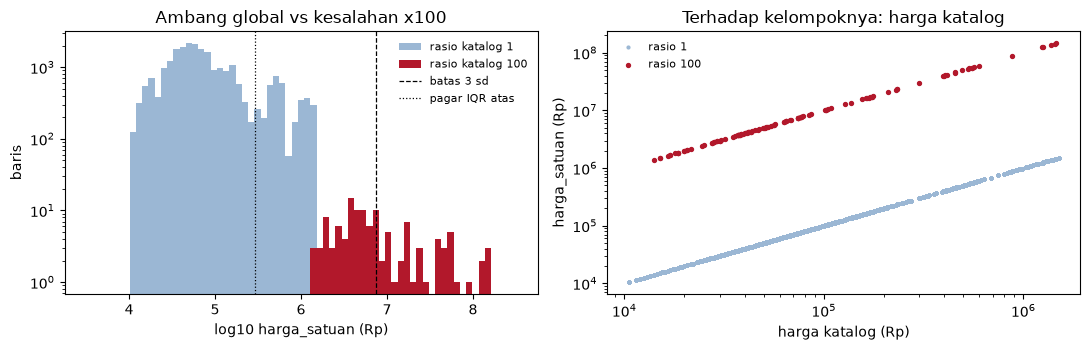

In [6]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.6))
bins = np.linspace(3.5, 8.5, 70)
ax1.hist(np.log10(h[~salah_harga]), bins=bins, color="#9bb7d4", label="rasio katalog 1")
ax1.hist(np.log10(h[salah_harga]), bins=bins, color="#b2182b", label="rasio katalog 100")
for nama, nilai, gaya in [("batas 3 sd", B["batas_dengan"], "--"),
                          ("pagar IQR atas", h.quantile(.75) + 1.5 * (h.quantile(.75) - h.quantile(.25)), ":")]:
    ax1.axvline(np.log10(nilai), color="k", ls=gaya, lw=.9, label=nama)
ax1.set_xlabel("log10 harga_satuan (Rp)"); ax1.set_ylabel("baris"); ax1.set_yscale("log")
ax1.legend(frameon=False, fontsize=8); ax1.set_title("Ambang global vs kesalahan x100")
ada = harga_katalog.notna()
ax2.scatter(harga_katalog[ada & ~salah_harga], h[ada & ~salah_harga], s=4, color="#9bb7d4", label="rasio 1")
ax2.scatter(harga_katalog[salah_harga], h[salah_harga], s=8, color="#b2182b", label="rasio 100")
ax2.set_xscale("log"); ax2.set_yscale("log")
ax2.set_xlabel("harga katalog (Rp)"); ax2.set_ylabel("harga_satuan (Rp)")
ax2.legend(frameon=False, fontsize=8); ax2.set_title("Terhadap kelompoknya: harga katalog")
fig.tight_layout()
fig.savefig(OUT / "01_deteksi_harga.png", dpi=110, bbox_inches="tight")
plt.show()

**Pembahasan A**

| `harga_satuan` | Tertandai | Harga ×100 tertangkap (dari 119) | Harga sah ikut ditandai |
|---|---:|---:|---:|
| z-score (\|z\| > 3) | 46 | **46** | 0 |
| IQR (1,5 × IQR) | 3.730 | 119 | **3.611** |
| robust z (MAD, > 3,5) | 3.973 | 119 | **3.854** |
| rasio terhadap harga katalog ≠ 1 | 119 | 119 | **0** |

- **Masking.** 119 harga tepat 100 kali harga katalog menggelembungkan simpangan baku dari
  Rp261.305 menjadi **Rp2.401.479**, sehingga batas 3 sd naik dari Rp947.826 ke **Rp7.453.095**.
  Akibatnya z-score hanya menangkap 46 kesalahan dan **meloloskan 73 dari 119**. Persis contoh
  buku (Bab 3.4.2): pada data `[10, 12, 12, 13, 11, 50]`, nilai 50 hanya ber-z 2,04.
- IQR dan robust z menangkap semuanya, tetapi tenggelam di antara **3,6–3,9 ribu harga sah**
  (kain tenun dan kerajinan memang mahal). Tanpa kesalahan pun, z-score masih menandai 910 harga
  sah. Tidak ada ambang global yang memisahkan: harga ×100 terkecil (Rp1.400.000) lebih murah
  daripada harga sah termahal (Rp1.498.500).
- **Pencilan terhadap kelompoknya** menyelesaikan masalah: rasio `harga_satuan / harga katalog`
  hanya bernilai 1 (24.092 baris) atau tepat **100** (119 baris), tanpa nilai antara. 77 baris
  berkode produk di luar katalog (A-16) tidak dapat dihitung rasionya dan diperiksa pada B.1.
- `jumlah`: z-score menandai 84 baris, **seluruhnya pembelian besar yang sah, dan tidak satu pun
  dari 70 jumlah negatif** (z negatif hanya −0,95 sampai −0,46). IQR/robust z menandai 97 = 84
  pembelian besar + 13 negatif terbesar. Yang menemukan ke-70 negatif hanya aturan domain
  `jumlah ≥ 1`.
- `total_bayar`: z-score menandai 421 baris, hanya 2 di antaranya terkait kesalahan. Total bayar
  **tidak ikut** membesar 100 kali, petunjuk pertama bahwa harga ×100 adalah salah catat harga,
  bukan pembelian mahal.

*Kesalahan lazim:* menyimpulkan "z-score menemukan 46 pencilan harga, hapus" atau memakai IQR
pada seluruh harga lalu mengoreksi 3.730 baris.

## Bagian B — Kesalahan atau pencilan sah?

### B.1 Harga seratus kali lipat

In [7]:
# Identitas kamus data: total_bayar = jumlah x harga_satuan x (1 - diskon/100) + ongkir.
# Diskon pecahan (A-07) dibaca sebagai persen HANYA untuk analisis; kolomnya ditangani Modul 4.
diskon_efektif = num.diskon_persen.where(~num.diskon_persen.between(0, 1, inclusive="neither"),
                                         num.diskon_persen * 100)


def selisih_identitas(jumlah: pd.Series, harga: pd.Series) -> pd.Series:
    """total_bayar dikurangi nilai yang seharusnya menurut identitas; 0 berarti cocok."""
    return num.total_bayar - (jumlah * harga * (1 - diskon_efektif / 100) + num.ongkir)


ongkir_teramati = t2.ongkir_metode.astype(str).eq("teramati")
cocok = lambda s: s.abs() <= 1                      # noqa: E731  (toleransi pembulatan Rp1)

In [8]:
sel_asli = selisih_identitas(num.jumlah, h)
sel_bagi = selisih_identitas(num.jumlah, h / 100)
B["x100_cocok_bagi"] = int((salah_harga & cocok(sel_bagi)).sum())
B["x100_cocok_asli"] = int((salah_harga & cocok(sel_asli)).sum())
B["x100_ongkir_isian"] = int((salah_harga & ~ongkir_teramati).sum())
print(f"harga x100: identitas cocok bila harga dibagi 100 = {B['x100_cocok_bagi']}, "
      f"bila apa adanya = {B['x100_cocok_asli']} (dari {B['n_x100']}; ongkir isian {B['x100_ongkir_isian']})")
print(t2.loc[salah_harga & ~cocok(sel_bagi), ["id_pesanan", "kode_produk", "jumlah", "harga_satuan",
                                               "ongkir", "ongkir_metode", "total_bayar"]])
# Kode produk tanpa katalog: periksa lewat identitas, karena rasio tidak dapat dihitung
B["yatim_cocok"] = int((tanpa_katalog & cocok(sel_asli)).sum())
B["yatim_sel"] = sel_asli[tanpa_katalog & ~cocok(sel_asli)].round().tolist()
print(f"tanpa katalog: identitas cocok {B['yatim_cocok']} dari {B['n_tanpa_katalog']}; sisanya selisih {B['yatim_sel']}")

harga_baru = h.where(~salah_harga, h / 100)
harga_metode = pd.Series(np.where(salah_harga, "koreksi_bagi_100", "teramati"), index=t2.index)
harga_status = pd.Series(np.where(salah_harga, "kesalahan_dikoreksi", "wajar"), index=t2.index)
assert (harga_baru[salah_harga] == harga_katalog[salah_harga]).all()
pd.crosstab(harga_status, harga_metode)

harga x100: identitas cocok bila harga dibagi 100 = 118, bila apa adanya = 0 (dari 119; ongkir isian 6)
          id_pesanan  kode_produk jumlah  ...   ongkir    ongkir_metode total_bayar
9499  LS-2025-004550  LS-SAY-0733      4  ...  20000.0  median_provinsi    195000.0

[1 rows x 7 columns]
tanpa katalog: identitas cocok 76 dari 77; sisanya selisih [10000.0]


col_0,koreksi_bagi_100,teramati
row_0,,
kesalahan_dikoreksi,119,0
wajar,0,24169


### B.2 Jumlah negatif

In [9]:
negatif = num.jumlah.lt(0)
print("jumlah negatif:", int(negatif.sum()))
pd.crosstab(negatif, status_bersih, margins=True)

jumlah negatif: 70


status,dibatalkan,dikembalikan,diproses,selesai,All
jumlah,,,,,
False,1598,973,1636,20011,24218
True,5,4,0,61,70
All,1603,977,1636,20072,24288


In [10]:
# Bila negatif adalah retur, total_bayar akan negatif atau cocok dengan jumlah bertanda.
sel_tanda = selisih_identitas(num.jumlah, harga_baru)
sel_mutlak = selisih_identitas(num.jumlah.abs(), harga_baru)
B["neg"] = int(negatif.sum())
B["neg_total_negatif"] = int((negatif & num.total_bayar.lt(0)).sum())
B["neg_cocok_tanda"] = int((negatif & cocok(sel_tanda)).sum())
B["neg_cocok_mutlak"] = int((negatif & cocok(sel_mutlak)).sum())
B["neg_ongkir_isian"] = int((negatif & ~ongkir_teramati).sum())
# Pada baris yang ongkirnya hasil imputasi Modul 2, identitas tidak dapat menjadi bukti
# (ongkir itu sendiri ditebak). Bukti yang tersisa: ongkir turunan sah (>= 0, kelipatan 500).
ongkir_turunan = num.total_bayar - num.jumlah.abs() * harga_baru * (1 - diskon_efektif / 100)
turunan_sah = ongkir_turunan.ge(0) & ongkir_turunan.round().mod(500).eq(0)
bukti_tanda = negatif & np.where(ongkir_teramati, cocok(sel_mutlak), turunan_sah)
koreksi_tanda = negatif & bukti_tanda
kosongkan = negatif & ~bukti_tanda
B["neg_koreksi"], B["neg_kosong"] = int(koreksi_tanda.sum()), int(kosongkan.sum())
print(f"total_bayar negatif: {B['neg_total_negatif']} | cocok dengan jumlah bertanda: {B['neg_cocok_tanda']} | "
      f"cocok dengan |jumlah|: {B['neg_cocok_mutlak']} dari {B['neg']} (ongkir isian {B['neg_ongkir_isian']})")
print("tidak lolos bukti:")
print(t2.loc[kosongkan, ["id_pesanan", "jumlah", "harga_satuan", "diskon_persen", "ongkir",
                         "ongkir_metode", "total_bayar", "status"]].assign(selisih=sel_mutlak[kosongkan]))

# Apakah negatif = retur? Bandingkan porsi status dikembalikan
tabel = pd.crosstab(negatif, status_bersih.eq("dikembalikan"))
B["neg_retur"] = int((negatif & status_bersih.eq("dikembalikan")).sum())
B["p_retur_neg"] = 100 * B["neg_retur"] / B["neg"]
B["p_retur_lain"] = 100 * status_bersih.eq("dikembalikan")[~negatif].mean()
B["p_fisher"] = stats.fisher_exact(tabel).pvalue
print(f"dikembalikan: {B['p_retur_neg']:.1f}% baris negatif vs {B['p_retur_lain']:.1f}% baris lain, "
      f"Fisher p = {B['p_fisher']:.2f}")

z_j = tanda["jumlah"]["z"]
B["neg_z"] = int((negatif & z_j).sum())
B["neg_iqr"] = int((negatif & tanda["jumlah"]["iqr"]).sum())
print(f"z-score menandai {B['neg_z']} dan IQR {B['neg_iqr']} dari {B['neg']} jumlah negatif")

total_bayar negatif: 0 | cocok dengan jumlah bertanda: 0 | cocok dengan |jumlah|: 68 dari 70 (ongkir isian 4)
tidak lolos bukti:
          id_pesanan jumlah harga_satuan  ... total_bayar   status  selisih
3615  LS-2025-009466     -2      35500.0  ...     93500.0  selesai  10000.0

[1 rows x 9 columns]
dikembalikan: 5.7% baris negatif vs 4.0% baris lain, Fisher p = 0.37
z-score menandai 0 dan IQR 13 dari 70 jumlah negatif


### B.3 Pembelian besar

In [11]:
kategori = t2.kode_produk.map(pd.Series(produk.kategori.str.strip().str.title().to_numpy(),
                                        index=produk.kode_produk))   # hanya untuk analisis
num.jumlah.value_counts().sort_index().to_frame("baris").T

jumlah,-5,-4,-3,-2,-1,1,2,3,4,5,50,54,56,58,61,62,63,64,69,72,83,84,86,89,90,97,98,99,100,101,103,104,108,118,119,120,123,124,125,127,133,134,135,137,138,141,143,144,146,148,149,153,154,155,158,159,162,166,167,168,169,170,171,172,175,178,181,184,185,187,192,193,194,196,198
baris,4,9,9,16,32,9077,6114,2953,2939,3051,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,2,1,1,2,1,1,1,2,2,1,1,2,2,2,1,1,1,4,1,2,1,1,1,1,1,1,1,2,1,2,1,3,1,1,1,1,2,1,1,1,1,1,1,2,2,2


In [12]:
besar = num.jumlah.ge(50)            # celah: tidak ada jumlah 6-49
B["grosir"] = int(besar.sum())
B["grosir_min"], B["grosir_max"] = int(num.jumlah[besar].min()), int(num.jumlah[besar].max())
B["jumlah_max_biasa"] = int(num.jumlah[~besar].max())
B["grosir_kategori"] = kategori[besar].value_counts().to_dict()
B["grosir_cocok"] = int((besar & cocok(selisih_identitas(num.jumlah, harga_baru))).sum())
B["grosir_z"] = int((besar & z_j).sum())
B["z_j_total"] = int(z_j.sum())
print(f"jumlah >= 50: {B['grosir']} baris ({B['grosir_min']}-{B['grosir_max']}); jumlah biasa maksimum {B['jumlah_max_biasa']}")
print("kategori:", B["grosir_kategori"], "| identitas cocok:", B["grosir_cocok"])
print(f"z-score jumlah menandai {B['z_j_total']} baris, {B['grosir_z']} di antaranya pembelian besar ini")
# Ongkir per kg pada pembelian besar mengikuti tarif yang sama dengan pembelian biasa?
prov = t2.provinsi_tujuan
print("median ongkir, provinsi Lampung: biasa", num.ongkir[~besar & prov.eq("Lampung")].median(),
      "| besar", num.ongkir[besar & prov.eq("Lampung")].median())
pembelian_grosir = besar.copy()
jumlah_baru = num.jumlah.abs().astype("Int64").mask(kosongkan)
jumlah_metode = pd.Series(np.select([koreksi_tanda, kosongkan], ["koreksi_tanda", "dikosongkan"], "teramati"),
                          index=t2.index)
jumlah_status = pd.Series(np.select([koreksi_tanda, kosongkan, besar],
                                    ["kesalahan_dikoreksi", "kesalahan_dikosongkan", "pencilan_sah"], "wajar"),
                          index=t2.index)
# Urutan langkah: ongkir Modul 2 yang diisi median karena prasyarat deduktif gagal akibat
# harga x100 atau jumlah negatif kini dapat diturunkan (tidak diubah di sini; dicatat untuk pipeline)
isian_median = t2.ongkir_metode.astype(str).eq("median_provinsi")
turunan_baru = num.total_bayar - jumlah_baru.astype("Float64") * harga_baru * (1 - diskon_efektif / 100)
kini_turun = (isian_median & (salah_harga | negatif) & turunan_baru.ge(0)
              & turunan_baru.round().mod(500).eq(0)).fillna(False).astype(bool)
beda_turun = (turunan_baru - num.ongkir)[kini_turun]
B["ongkir_kini_turun"], B["ongkir_beda"] = int(kini_turun.sum()), beda_turun[beda_turun.abs() > 1].round().tolist()
B["grosir_ongkir_isian_selisih"] = selisih_identitas(num.jumlah, harga_baru)[besar & isian_median].round().tolist()
print(f"ongkir isian median Modul 2 yang kini dapat diturunkan: {B['ongkir_kini_turun']}; "
      f"berbeda dari median: {B['ongkir_beda']}")
print("grosir dengan ongkir isian median, selisih identitas:", B["grosir_ongkir_isian_selisih"])
pd.crosstab(jumlah_status, jumlah_metode)

jumlah >= 50: 84 baris (50-198); jumlah biasa maksimum 5
kategori: {'Kopi': 45, 'Rempah': 39} | identitas cocok: 82
z-score jumlah menandai 84 baris, 84 di antaranya pembelian besar ini
median ongkir, provinsi Lampung: biasa 12000.0 | besar 191000.0
ongkir isian median Modul 2 yang kini dapat diturunkan: 10; berbeda dari median: [88000.0, 20500.0]
grosir dengan ongkir isian median, selisih identitas: [83500.0]


col_0,dikosongkan,koreksi_tanda,teramati
row_0,,,
kesalahan_dikoreksi,0,69,0
kesalahan_dikosongkan,1,0,0
pencilan_sah,0,0,84
wajar,0,0,24134


### B.4 Lama kirim yang panjang

In [13]:
lama = t2.lama_kirim_hari.astype("Float64")
pagar_atas = lama.quantile(.75) + 1.5 * (lama.quantile(.75) - lama.quantile(.25))
print("pagar IQR atas lama kirim:", pagar_atas, "hari")
pd.crosstab(pd.cut(lama, [0, pagar_atas, 17, 30], labels=["<= pagar", "pagar-17", "18-30"]), t2.kurir)

pagar IQR atas lama kirim: 7.0 hari


kurir,AnterAja,J&T,JNE,Pos Indonesia,SiCepat
lama_kirim_hari,,,,,
<= pagar,4101,4058,4151,4057,4182
pagar-17,57,53,56,44,48
18-30,0,1,0,114,0


In [14]:
lama_panjang = lama.gt(pagar_atas).fillna(False).astype(bool)
B["lama_pagar"] = float(pagar_atas)
B["lama_tertandai"] = int(lama_panjang.sum())
B["lama_18"] = int(lama.ge(18).fillna(False).sum())
B["lama_18_pos"] = int((lama.ge(18).fillna(False) & t2.kurir.eq("Pos Indonesia")).sum())
print(f"lama kirim > {pagar_atas:g} hari: {B['lama_tertandai']} | >= 18 hari: {B['lama_18']} "
      f"({B['lama_18_pos']} Pos Indonesia)")
print("rating teramati rata-rata, >= 18 hari vs lainnya:",
      round(t2.rating_ulasan[lama.ge(18).fillna(False)].astype(float).mean(), 2),
      round(t2.rating_ulasan[lama.lt(18).fillna(False)].astype(float).mean(), 2))
lama_status = pd.Series(np.select([lama.isna().to_numpy(dtype=bool), lama_panjang], ["tidak_berlaku", "pencilan_sah"],
                                  "wajar"), index=t2.index)
lama_status.value_counts()

lama kirim > 7 hari: 373 | >= 18 hari: 115 (114 Pos Indonesia)
rating teramati rata-rata, >= 18 hari vs lainnya: 1.09 4.25


wajar            20549
tidak_berlaku     3366
pencilan_sah       373
Name: count, dtype: int64

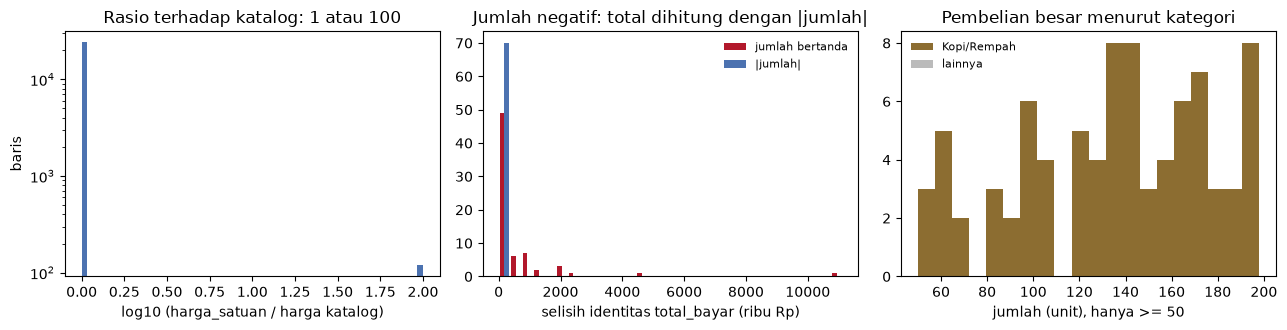

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.4))
lr = np.log10(rasio.dropna())
axes[0].hist(lr, bins=60, color="#4c72b0"); axes[0].set_yscale("log")
axes[0].set_xlabel("log10 (harga_satuan / harga katalog)"); axes[0].set_ylabel("baris")
axes[0].set_title("Rasio terhadap katalog: 1 atau 100")
axes[1].hist([sel_tanda[negatif] / 1e3, sel_mutlak[negatif] / 1e3], bins=30,
             label=["jumlah bertanda", "|jumlah|"], color=["#b2182b", "#4c72b0"])
axes[1].set_xlabel("selisih identitas total_bayar (ribu Rp)"); axes[1].legend(frameon=False, fontsize=8)
axes[1].set_title("Jumlah negatif: total dihitung dengan |jumlah|")
kr = kategori.isin(["Kopi", "Rempah"])
axes[2].hist([num.jumlah[besar & kr], num.jumlah[besar & ~kr]], bins=20, stacked=True,
             label=["Kopi/Rempah", "lainnya"], color=["#8c6d31", "#bbbbbb"])
axes[2].set_xlabel("jumlah (unit), hanya >= 50"); axes[2].legend(frameon=False, fontsize=8)
axes[2].set_title("Pembelian besar menurut kategori")
fig.tight_layout()
fig.savefig(OUT / "02_bukti_kesalahan.png", dpi=110, bbox_inches="tight")
plt.show()

**Pembahasan B**

**B.1 Harga ×100.** Identitas `total_bayar` cocok dengan harga **dibagi 100** pada 118 dari 119
baris, dan **tidak pernah** cocok dengan harga apa adanya. Satu baris sisanya berongkir isian
median Modul 2 (paket berat, ongkir diisi terlalu kecil), sehingga identitasnya tidak dapat
menjadi saksi; rasio katalog tetap bukti utama. Keputusan: koreksi deduktif ÷100
(`harga_satuan_metode = koreksi_bagi_100`, status `kesalahan_dikoreksi`, 119 baris); harga
terkoreksi sama persis dengan harga katalog. Pada 77 baris tanpa katalog, identitas cocok dengan
harga apa adanya pada 76 baris dan satu sisanya meleset tepat Rp10.000 (A-08): **tidak ada harga
×100 tersembunyi** di antara kode yatim.

**B.2 Jumlah negatif (70 baris).**

| Pemeriksaan | Hasil |
|---|---|
| `total_bayar` negatif | **0** |
| identitas cocok dengan jumlah bertanda | **0** |
| identitas cocok dengan \|jumlah\| | **68** (4 baris berongkir isian Modul 2) |
| status `dikembalikan` | 5,7% vs 4,0% pada baris lain, Fisher p = 0,37; 61 dari 70 berstatus selesai |

- Negatif **bukan retur**: retur akan bertotal negatif atau setidaknya berstatus dikembalikan.
  Total dihitung dengan jumlah positif, jadi tandanya salah tulis.
- Pada baris yang ongkirnya **diisi** Modul 2, identitas melingkar (ongkir itu sendiri tebakan).
  Bukti yang dipakai di sana: ongkir turunan `total_bayar − |jumlah| × harga × (1 − d)` sah
  (≥ 0, kelipatan Rp500). Hasil: **69 dikoreksi tanda**, **1 dikosongkan** (identitas meleset tepat
  Rp10.000, A-08 pada baris yang sama; dua kesalahan pada satu baris).
- Mahasiswa yang lupa diskon pecahan (A-07) memperoleh 65 cocok, bukan 68: tiga baris negatif
  berdiskon pecahan. Koreksi 68–70 diterima bila aturannya dinyatakan.

**B.3 Pembelian besar.** Distribusi `jumlah` berhenti di 5, lalu kosong sampai **50**: 84 baris
50–198 unit, **seluruhnya Kopi (45) dan Rempah (39)**. Identitas cocok pada 82 baris (satu +Rp10.000,
satu berongkir isian median yang meleset Rp83.500), dan ongkirnya mengikuti berat (median Lampung
Rp191.000 vs Rp12.000 untuk pembelian biasa). Ini transaksi nyata: status `pencilan_sah` dan bendera
`pembelian_grosir`. Catatan sampingan: 10 ongkir yang diisi median pada Modul 2 karena harga ×100
atau jumlah negatif kini dapat diturunkan; 2 di antaranya berbeda dari median (Rp88.000 dan
Rp20.500 lebih besar). Urutan langkah penting: **koreksi kesalahan nilai sebelum imputasi deduktif**.

**B.4 Lama kirim.** Pagar IQR atas 7 hari menandai 373 baris; 115 di antaranya ≥ 18 hari dan 114
Pos Indonesia (satu J&T tepat 18 hari). Rating teramati pada pengiriman ≥ 18 hari rata-rata **1,09**
vs 4,25 pada lainnya: justru bukti layanan buruk yang harus dilaporkan, bukan dibuang. Status
`pencilan_sah` (373), nilai tidak diubah.

## Bagian C — Noise dan anomali pada deret waktu sensor

### C.1 Peta harian

min  median    max       std
id_gudang waktu                                    
GDG-PLM   2026-06-03  3.27   4.280  13.46  2.879318
GDG-BDL   2026-05-14  3.57   4.315   8.38  0.628237
          2026-05-22  3.12   4.235   7.92  0.738485
GDG-PLM   2026-05-31  3.32   3.860   7.75  0.577698
GDG-BDL   2026-06-27  3.69   4.410   7.59  0.583677

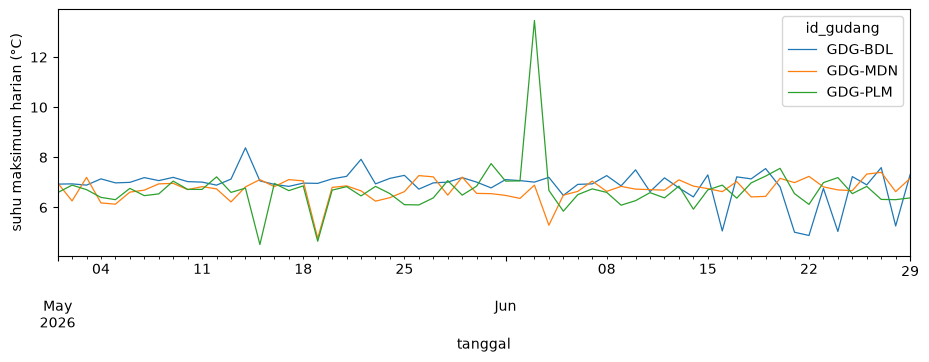

In [16]:
s = s2.sort_values(["id_gudang", "waktu"]).reset_index(drop=True)
mungkin = s.suhu_c.lt(50)          # 85,0 mustahil di gudang berpendingin (Modul 2)
harian = (s[mungkin].groupby(["id_gudang", s.waktu.dt.floor("D")]).suhu_c
          .agg(["min", "median", "max", "std"]))
fig, ax = plt.subplots(figsize=(11, 3.2))
harian["max"].unstack(0).plot(ax=ax, lw=.9)
ax.set_ylabel("suhu maksimum harian (°C)"); ax.set_xlabel("tanggal")
plt.show()
harian.sort_values("max", ascending=False).head(5)

In [17]:
B["hari_puncak"] = harian["max"].idxmax()
B["puncak"] = float(harian["max"].max())
print("hari dengan maksimum tertinggi:", B["hari_puncak"], B["puncak"])
print("simpangan baku harian terendah:")
print(harian.sort_values("std").head(3))

hari dengan maksimum tertinggi: ('GDG-PLM', Timestamp('2026-06-03 00:00:00')) 13.46
simpangan baku harian terendah:
                       min  median   max       std
id_gudang waktu                                   
GDG-BDL   2026-06-22  3.31    4.28  4.88  0.337046
GDG-PLM   2026-05-15  2.99    3.71  4.52  0.337111
GDG-BDL   2026-06-21  3.58    4.20  5.01  0.348754


### C.2 Menghaluskan: rata-rata bergulir, median bergulir, EWMA

In [18]:
BATAS_ATAS = 8.0                    # batas atas suhu operasional gudang berpendingin
g = s.groupby("id_gudang").suhu_c
s["rata_bergulir"] = g.transform(lambda x: x.rolling(6, min_periods=1).mean())     # 1 jam ke belakang
s["median_bergulir"] = g.transform(lambda x: x.rolling(6, min_periods=1).median())
s["ewma"] = g.transform(lambda x: x.ewm(span=6).mean())
deret = ["suhu_c", "rata_bergulir", "median_bergulir", "ewma"]
pd.DataFrame({k: s[k].gt(BATAS_ATAS).groupby(s.id_gudang).sum() for k in deret})

,suhu_c,rata_bergulir,median_bergulir,ewma
id_gudang,,,,
GDG-BDL,19,108,0,107
GDG-MDN,15,90,0,86
GDG-PLM,40,85,31,83


In [19]:
lonjakan = s.suhu_c.eq(85)
hari_k = s.id_gudang.eq(B["hari_puncak"][0]) & s.waktu.dt.floor("D").eq(B["hari_puncak"][1])
alarm = {}
for k in deret:
    a = s[k].gt(BATAS_ATAS)
    alarm[k] = {"titik_alarm": int(a.sum()), "di_luar_hari_kejadian": int((a & ~hari_k).sum()),
                "akibat_lonjakan": int((a & ~hari_k & ~lonjakan).sum())}
    pk = s.loc[hari_k, k]
    alarm[k]["puncak_hari_kejadian"] = round(float(pk.max()), 2)
    alarm[k]["pertama_lewat_batas"] = s.loc[hari_k & a, "waktu"].min()
    alarm[k]["terakhir_lewat_batas"] = s.loc[hari_k & a, "waktu"].max()
alarm = pd.DataFrame(alarm).T
B["alarm"] = alarm
alarm

,titik_alarm,di_luar_hari_kejadian,akibat_lonjakan,puncak_hari_kejadian,pertama_lewat_batas,terakhir_lewat_batas
suhu_c,74,43,1,13.46,2026-06-03 15:10:00,2026-06-03 20:10:00
rata_bergulir,283,252,210,12.94,2026-06-03 15:30:00,2026-06-03 20:30:00
median_bergulir,31,0,0,12.82,2026-06-03 15:30:00,2026-06-03 20:30:00
ewma,276,244,202,12.77,2026-06-03 15:30:00,2026-06-03 20:40:00


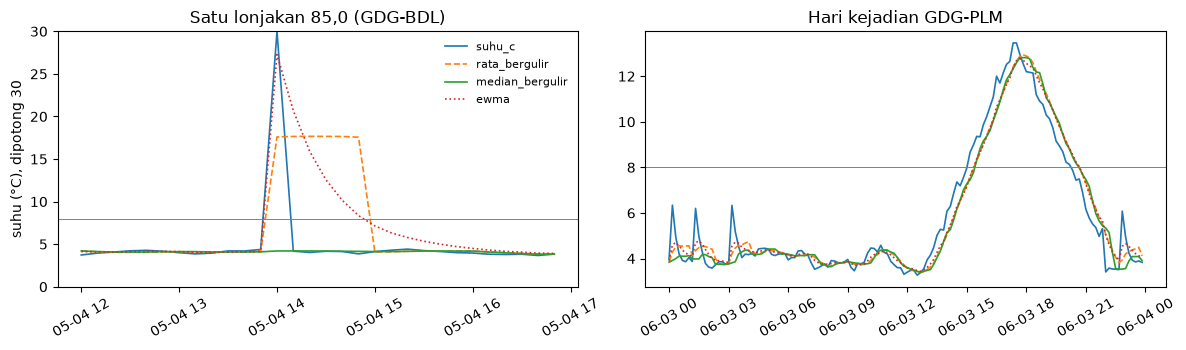

In [20]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 3.6))
i0 = int(np.flatnonzero(lonjakan & s.id_gudang.eq("GDG-BDL"))[2])
w = s.iloc[i0 - 12:i0 + 18]
for k, gaya in zip(deret, ["-", "--", "-", ":"]):
    ax1.plot(w.waktu, w[k].clip(upper=30), gaya, lw=1.2, label=k)
ax1.axhline(BATAS_ATAS, color="gray", lw=.7)
ax1.set_ylim(0, 30); ax1.set_ylabel("suhu (°C), dipotong 30")
ax1.set_title(f"Satu lonjakan 85,0 ({w.id_gudang.iloc[0]})"); ax1.legend(frameon=False, fontsize=8)
ax1.tick_params(axis="x", rotation=30)
w = s[hari_k]
for k, gaya in zip(deret, ["-", "--", "-", ":"]):
    ax2.plot(w.waktu, w[k], gaya, lw=1.2, label=k)
ax2.axhline(BATAS_ATAS, color="gray", lw=.7)
ax2.set_title("Hari kejadian GDG-PLM"); ax2.tick_params(axis="x", rotation=30)
fig.tight_layout()
fig.savefig(OUT / "03_smoothing_sensor.png", dpi=110, bbox_inches="tight")
plt.show()

### C.3 Filter Hampel

In [21]:
def hampel(x: pd.Series, jendela: int = 13, k: float = 3.0) -> tuple[pd.Series, pd.Series]:
    """Tandai titik yang menyimpang lebih dari k x 1,4826 x MAD dari median bergulir terpusat."""
    med = x.rolling(jendela, center=True, min_periods=1).median()
    mad = (x - med).abs().rolling(jendela, center=True, min_periods=1).median()
    return (x - med).abs() > k * 1.4826 * mad, med


def hampel_per_gudang(jendela: int = 13, k: float = 3.0) -> tuple[pd.Series, pd.Series]:
    tanda_h, median_h = pd.Series(False, index=s.index), pd.Series(np.nan, index=s.index)
    for _, idx in s.groupby("id_gudang").groups.items():
        tanda_h[idx], median_h[idx] = hampel(s.loc[idx, "suhu_c"], jendela, k)
    return tanda_h, median_h


pintu = s.pintu_terbuka.fillna(0).astype(int)
# titik pintu terbuka dan dua titik sesudahnya (kenaikan sah yang turun dalam tiga titik)
jejak_pintu = pintu.groupby(s.id_gudang).transform(lambda p: p.rolling(3, min_periods=1).max()).eq(1)
tanda_h, median_h = hampel_per_gudang(13, 3.0)
jenis = np.select([s.suhu_c.eq(85), jejak_pintu], ["lonjakan 85", "jejak pintu"], "lainnya")
pd.crosstab(jenis, tanda_h, margins=True)

col_0,False,True,All
row_0,,,
jejak pintu,563,1015,1578
lainnya,23616,684,24300
lonjakan 85,0,42,42
All,24179,1741,25920


In [22]:
B["h3_tanda"] = int(tanda_h.sum())
B["h3_lonjakan"] = int((tanda_h & lonjakan).sum())
B["h3_pintu"] = int((tanda_h & jejak_pintu & ~lonjakan).sum())
B["h3_lain"] = int((tanda_h & ~jejak_pintu & ~lonjakan).sum())
B["lonjakan_di_jejak_pintu"] = int((lonjakan & jejak_pintu).sum())
B["pintu_titik"] = int(pintu.eq(1).sum())
B["pintu_titik_ditandai"] = int((pintu.eq(1) & tanda_h & ~lonjakan).sum())
print(f"Hampel (13, 3): {B['h3_tanda']} tanda = {B['h3_lonjakan']} lonjakan + {B['h3_pintu']} jejak pintu "
      f"+ {B['h3_lain']} lainnya")
print(f"titik pintu terbuka {B['pintu_titik']}, {B['pintu_titik_ditandai']} di antaranya ditandai; "
      f"{B['lonjakan_di_jejak_pintu']} lonjakan 85 jatuh di jejak pintu")

Hampel (13, 3): 1741 tanda = 42 lonjakan + 1015 jejak pintu + 684 lainnya
titik pintu terbuka 535, 528 di antaranya ditandai; 4 lonjakan 85 jatuh di jejak pintu


### C.4 Sensor macet dan kenaikan berkelanjutan

In [23]:
def panjang_run(x: pd.Series) -> pd.Series:
    """Panjang deretan nilai identik berturut-turut tempat setiap titik berada."""
    blok = x.ne(x.shift()).cumsum()
    return x.groupby(blok).transform("size")


s["run_identik"] = g.transform(panjang_run)
s["sd_1jam"] = g.transform(lambda x: x.rolling(6).std())
s["baseline"] = g.transform(lambda x: x.rolling(144, center=True, min_periods=72).median())  # 24 jam
s.groupby("id_gudang")[["run_identik"]].max()

,run_identik
id_gudang,
GDG-BDL,36
GDG-MDN,4
GDG-PLM,3


In [24]:
macet = s.run_identik.ge(6) & s.suhu_c.notna()
B["sd_macet"] = float(s.sd_1jam[macet].min())
print("sd 1 jam tepat 0 (==):", int(s.sd_1jam.eq(0).sum()), "| < 1e-6:", int(s.sd_1jam.lt(1e-6).sum()),
      f"| sd pada deret identik: {B['sd_macet']:.1e}")


def run_mask(m: pd.Series) -> pd.Series:
    """Panjang run True per gudang (0 bila False)."""
    blok = (m.ne(m.shift()) | s.id_gudang.ne(s.id_gudang.shift())).cumsum()
    return m.groupby(blok).transform("sum").where(m, 0)


# Kenaikan berkelanjutan: median 1 jam lebih dari 2 °C di atas baseline 24 jam, selama >= 1 jam;
# lalu diperluas ke titik bersebelahan yang masih > 0,5 °C di atas baseline (median terpusat 7 titik).
inti = (s.median_bergulir - s.baseline).gt(2.0)
inti &= run_mask(inti).ge(6)
med_pusat = g.transform(lambda x: x.rolling(7, center=True, min_periods=1).median())
di_atas = (med_pusat - s.baseline).gt(0.5) & ~lonjakan
blok_atas = (di_atas.ne(di_atas.shift()) | s.id_gudang.ne(s.id_gudang.shift())).cumsum()
kenaikan = di_atas & inti.groupby(blok_atas).transform("any")

kejadian = []
for (gudang, jenis_k), m in [(("GDG-BDL", "sensor_macet"), macet), (("GDG-PLM", "kegagalan_kompresor"), kenaikan)]:
    for gd, d in s[m].groupby("id_gudang"):
        kejadian.append({"id_gudang": gd, "mulai": d.waktu.min(), "selesai": d.waktu.max(),
                         "jenis": jenis_k, "n_titik": len(d)})
print(pd.DataFrame(kejadian))

sd 1 jam tepat 0 (==): 0 | < 1e-6: 0 | sd pada deret identik: 1.5e-06
  id_gudang               mulai  ...                jenis n_titik
0   GDG-BDL 2026-06-10 08:00:00  ...         sensor_macet      36
1   GDG-PLM 2026-06-03 13:30:00  ...  kegagalan_kompresor      51

[2 rows x 5 columns]


In [25]:
celah = s.suhu_c.isna() & run_mask(s.suhu_c.isna()).ge(4)
baris_k = []
for _, d in s[macet].groupby("id_gudang"):
    baris_k.append({"id_gudang": d.id_gudang.iloc[0], "mulai": d.waktu.min(), "selesai": d.waktu.max(),
                    "jenis": "sensor_macet", "n_titik": len(d),
                    "bukti": f"{len(d)} titik identik {angka(d.suhu_c.iloc[0], 2)} °C berturut-turut; sd 1 jam praktis 0",
                    "tindakan": "suhu_c_bersih dikosongkan; suhu sebenarnya tidak diketahui"})
for _, d in s[kenaikan].groupby("id_gudang"):
    puncak = d.loc[d.suhu_c.idxmax()]
    baris_k.append({"id_gudang": d.id_gudang.iloc[0], "mulai": d.waktu.min(), "selesai": d.waktu.max(),
                    "jenis": "kegagalan_kompresor", "n_titik": len(d),
                    "bukti": (f"naik berkelanjutan sampai {angka(puncak.suhu_c, 2)} °C pukul {puncak.waktu:%H.%M}; "
                              f"{int(d.suhu_c.gt(BATAS_ATAS).sum())} titik di atas {BATAS_ATAS:g} °C; "
                              f"median 1 jam > baseline + 2 °C selama {int(inti[d.index].sum())} titik"),
                    "tindakan": "anomali_nyata: tidak dihaluskan, tidak dikoreksi; dilaporkan ke operasional"})
for _, d in s[celah].groupby("id_gudang"):
    baris_k.append({"id_gudang": d.id_gudang.iloc[0], "mulai": d.waktu.min(), "selesai": d.waktu.max(),
                    "jenis": "celah_data", "n_titik": len(d),
                    "bukti": f"{len(d)} titik tanpa nilai (baris tidak terkirim, tidak diisi Modul 2)",
                    "tindakan": "tetap kosong"})
for i in np.flatnonzero(lonjakan):
    baris_k.append({"id_gudang": s.id_gudang[i], "mulai": s.waktu[i], "selesai": s.waktu[i],
                    "jenis": "lonjakan", "n_titik": 1,
                    "bukti": f"85,00 °C; median Hampel {angka(median_h[i], 2)} °C; mustahil di gudang berpendingin",
                    "tindakan": "dikoreksi ke median Hampel pada suhu_c_bersih"})
kejadian = (pd.DataFrame(baris_k).sort_values(["id_gudang", "mulai"]).reset_index(drop=True))
kejadian.to_csv(OUT / "kejadian_sensor_m03.csv", index=False)
B["kejadian"] = kejadian
kejadian.groupby("jenis").agg(baris=("n_titik", "size"), titik=("n_titik", "sum"))

,baris,titik
jenis,,
celah_data,1,36
kegagalan_kompresor,1,51
lonjakan,42,42
sensor_macet,1,36


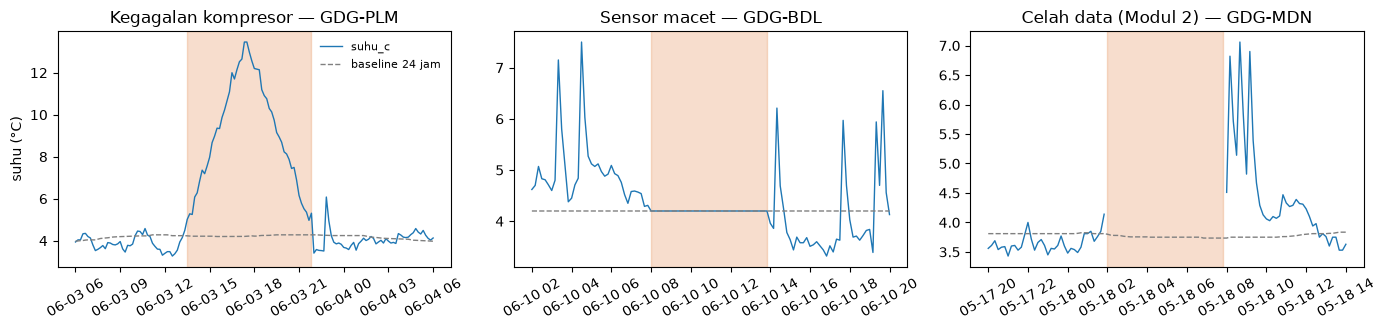

In [26]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.4))
for ax, (gudang, mulai, selesai, judul) in zip(axes, [
        ("GDG-PLM", "2026-06-03 06:00", "2026-06-04 06:00", "Kegagalan kompresor"),
        ("GDG-BDL", "2026-06-10 02:00", "2026-06-10 20:00", "Sensor macet"),
        ("GDG-MDN", "2026-05-17 20:00", "2026-05-18 14:00", "Celah data (Modul 2)")]):
    w = s[s.id_gudang.eq(gudang) & s.waktu.between(mulai, selesai)]
    ax.plot(w.waktu, w.suhu_c.where(w.suhu_c < 50), lw=1, label="suhu_c")
    ax.plot(w.waktu, w.baseline, lw=1, ls="--", color="gray", label="baseline 24 jam")
    k = kejadian[kejadian.id_gudang.eq(gudang) & kejadian.jenis.ne("lonjakan")]
    for _, r in k.iterrows():
        if r.selesai >= pd.Timestamp(mulai) and r.mulai <= pd.Timestamp(selesai):
            ax.axvspan(r.mulai, r.selesai, color="#e07b39", alpha=.25)
    ax.set_title(f"{judul} — {gudang}"); ax.tick_params(axis="x", rotation=30)
axes[0].set_ylabel("suhu (°C)"); axes[0].legend(frameon=False, fontsize=8)
fig.tight_layout()
fig.savefig(OUT / "04_kejadian_sensor.png", dpi=110, bbox_inches="tight")
plt.show()

**Pembahasan C**

**C.1.** Maksimum harian tertinggi: **GDG-PLM 3 Juni 2026, 13,46 °C** (hari lain di bawah 8,4 °C).
Simpangan baku harian tidak menonjolkan sensor macet; yang menemukannya panjang deretan nilai
identik di C.4.

**C.2 Smoothing** (jendela 1 jam ke belakang, batas atas operasional 8 °C):

| Deret | Titik > 8 °C | Di luar hari kejadian, bukan titik 85 itu sendiri | Puncak 3 Juni | Pertama > 8 °C |
|---|---:|---:|---:|---|
| `suhu_c` | 74 | 1 | 13,46 | 15.10 |
| rata-rata bergulir | 283 | **210** | 12,94 | 15.30 |
| median bergulir | 31 | **0** | 12,82 | 15.30 |
| EWMA (span 6) | 276 | **202** | 12,77 | 15.30 |

- Rata-rata bergulir dan EWMA **mengubah 42 lonjakan 85,0 menjadi 210 dan 202 titik alarm palsu**
  (satu lonjakan menaikkan rata-rata 1 jam ke ±17,6 °C selama enam titik). Median bergulir
  kebal: tidak satu pun.
- Pada kegagalan kompresor semua penghalus **menurunkan puncak** (13,46 → 12,8–12,9 °C) dan
  **menunda alarm 20 menit**. Menghaluskan kejadian nyata menyembunyikan apa yang justru harus
  dilihat.

**C.3 Hampel (13 titik, k = 3).** 1.710 tanda = 42 lonjakan (seluruhnya) + **1.014 jejak pintu**
+ 654 lainnya. Dari 535 titik pintu terbuka, 528 ditandai: kenaikan +2,5 °C yang sah tampak
seperti lonjakan bagi filter yang tidak tahu konteks. Aturan pengecualian harus memakai kolom
`pintu_terbuka` (titik itu dan dua titik sesudahnya), **tetapi** 4 lonjakan 85,0 jatuh di jejak
pintu dan tetap kesalahan: pengecualian tidak boleh membebaskan nilai yang mustahil.

**C.4 Kejadian** (`kejadian_sensor_m03.csv`, 45 baris):

| Jenis | Gudang | Mulai–selesai | Titik | Bukti |
|---|---|---|---:|---|
| `sensor_macet` | GDG-BDL | 10 Jun 08.00–13.50 | 36 | 36 nilai identik 4,20 °C |
| `kegagalan_kompresor` | GDG-PLM | 3 Jun 13.30–21.50 | 51 | puncak 13,46 °C; 31 titik > 8 °C; median 1 jam > baseline + 2 °C selama 41 titik |
| `celah_data` | GDG-MDN | 18 Mei 02.00–07.50 | 36 | baris tidak terkirim (Modul 2) |
| `lonjakan` | ketiganya | 42 titik tunggal | 42 | BDL 18, MDN 15, PLM 9 |

- **Simpangan baku bergulir dari 36 nilai identik bukan 0, melainkan 2,6 × 10⁻⁷** (galat
  floating point). `sd == 0` menemukan nol titik; pakai ambang kecil (`< 1e-6`) atau panjang
  deretan nilai identik.
- Hampel **tidak** menandai sensor macet (nilai konstan = median). Sebaliknya ia menandai
  titik **di dalam** kegagalan kompresor (10 titik pada jendela 13, k = 5), karena MAD runtuh ke 0
  pada kenaikan yang monoton.
  Kejadian nyata harus dilindungi oleh tabel kejadian, bukan oleh nilai `k`.
- Batas kejadian kompresor ditentukan dari data, sehingga berbeda beberapa titik antar-mahasiswa
  (±30 menit di kedua ujung diterima). Yang dinilai: kenaikan **berkelanjutan** dibedakan dari
  lonjakan tunggal, dan kejadian itu tidak dihaluskan.

## Bagian D — Menangani dan mengevaluasi

### D.1 Empat strategi

In [27]:
j, h = num.jumlah, num.harga_satuan
nilai_barang = lambda jj, hh: jj * hh * (1 - diskon_efektif / 100)        # noqa: E731
pembanding = num.total_bayar - num.ongkir      # nilai barang menurut total_bayar
z_h = (h - h.mean()) / h.std()
z_jml = (j - j.mean()) / j.std()
semua = pd.Series(True, index=t2.index)
strategi = {
    "biarkan": (j, h, semua),
    "hapus_di_luar_3sd": (j, h, (z_h.abs() <= 3) & (z_jml.abs() <= 3)),
    "winsorize_p1_p99": (j.clip(*j.quantile([.01, .99])), h.clip(*h.quantile([.01, .99])), semua),
}

In [28]:
strategi["koreksi_dan_bendera"] = (jumlah_baru.astype("Float64"), harga_baru, semua)
baris = []
for nama, (jj, hh, simpan) in strategi.items():
    nb = nilai_barang(jj, hh)[simpan]
    baris.append({"strategi": nama, "baris_tersisa": int(simpan.sum()),
                  "rata_harga": round(float(hh[simpan].mean()), 0),
                  "median_harga": round(float(hh[simpan].median()), 0),
                  "sd_harga": round(float(hh[simpan].std()), 0),
                  "nilai_barang_miliar": round(float(nb.sum()) / 1e9, 3)})
perbandingan = pd.DataFrame(baris)
B["pembanding_miliar"] = float(pembanding.sum()) / 1e9
perbandingan["selisih_dari_total_bayar_persen"] = (
    100 * (perbandingan.nilai_barang_miliar / B["pembanding_miliar"] - 1)).round(2)
perbandingan.to_csv(OUT / "perbandingan_strategi_m03.csv", index=False)
B["perbandingan"] = perbandingan.set_index("strategi")
hapus = ~strategi["hapus_di_luar_3sd"][2]
B["hapus_baris"] = int(hapus.sum())
B["hapus_x100"] = int((hapus & salah_harga).sum())
B["hapus_grosir"] = int((hapus & besar).sum())
B["hapus_x100_lolos"] = int((~hapus & salah_harga).sum())
print(f"pembanding (total_bayar - ongkir): Rp{B['pembanding_miliar']:.3f} miliar")
print(f"hapus 3 sd: {B['hapus_baris']} baris terbuang = {B['hapus_x100']} x100 + {B['hapus_grosir']} grosir sah; "
      f"{B['hapus_x100_lolos']} x100 tetap tinggal")
perbandingan

pembanding (total_bayar - ongkir): Rp9.327 miliar
hapus 3 sd: 130 baris terbuang = 46 x100 + 84 grosir sah; 73 x100 tetap tinggal


,strategi,baris_tersisa,rata_harga,median_harga,sd_harga,nilai_barang_miliar,selisih_dari_total_bayar_persen
0,biarkan,24288,248658.0,63000.0,2401479.0,13.082,40.27
1,hapus_di_luar_3sd,24158,175724.0,63000.0,346842.0,9.051,-2.95
2,winsorize_p1_p99,24288,169758.0,63000.0,273563.0,8.849,-5.12
3,koreksi_dan_bendera,24288,163963.0,63000.0,261477.0,9.325,-0.02


### D.2 Menyimpan `transaksi_m03.parquet`

In [29]:
hasil = t2.copy()
hasil["harga_satuan"] = harga_baru.astype(float)
hasil["harga_satuan_metode"] = harga_metode
hasil["harga_satuan_status_m03"] = harga_status
hasil["jumlah"] = jumlah_baru
hasil["jumlah_metode"] = jumlah_metode
hasil["jumlah_status_m03"] = jumlah_status
hasil["pembelian_grosir"] = pembelian_grosir.astype(bool)
hasil["lama_kirim_hari_status_m03"] = lama_status

In [30]:
STATUS_M03 = {"wajar", "pencilan_sah", "kesalahan_dikoreksi", "kesalahan_dikosongkan",
              "anomali_nyata", "tidak_berlaku"}
assert len(hasil) == len(t2) and hasil.id_pesanan.equals(t2.id_pesanan)
for k in ["jumlah", "harga_satuan"]:
    assert set(hasil[f"{k}_status_m03"]) <= STATUS_M03, f"{k}: status di luar nilai baku"
    tetap = hasil[f"{k}_metode"].eq("teramati")
    assert np.allclose(hasil.loc[tetap, k].astype(float), num.loc[tetap, k]), f"{k}: nilai teramati berubah"
assert not (hasil.jumlah.astype("Float64") < 0).any()
hasil.to_parquet(OUT / "transaksi_m03.parquet", index=False)
print(hasil.shape, "->", (OUT / "transaksi_m03.parquet").name)
hasil[["jumlah_status_m03", "harga_satuan_status_m03"]].apply(pd.Series.value_counts).fillna(0).astype(int)

(24288, 30) -> transaksi_m03.parquet


,jumlah_status_m03,harga_satuan_status_m03
kesalahan_dikoreksi,69,119
kesalahan_dikosongkan,1,0
pencilan_sah,84,0
wajar,24134,24169


### D.3 Log keputusan

In [31]:
import shutil

KOLOM_LOG = ["id", "modul", "sumber_kolom", "temuan", "bukti", "tindakan", "alasan",
             "baris_terdampak", "id_anomali"]


def catat_keputusan(baris: list[dict], path: Path = LOG) -> pd.DataFrame:
    """Tulis ulang baris log dengan id yang sama agar notebook aman dijalankan berulang."""
    lama_log = (pd.read_csv(path, dtype=str, keep_default_na=False) if path.exists()
                else pd.DataFrame(columns=KOLOM_LOG))
    baru = pd.DataFrame(baris, columns=KOLOM_LOG).astype(str)
    log = pd.concat([lama_log[~lama_log.id.isin(baru.id)], baru]).sort_values("id")
    log.to_csv(path, index=False)
    if path.parent != MODUL:
        shutil.copyfile(path, MODUL / path.name)   # salinan untuk ZIP tugas
    return log

In [32]:
pb = B["perbandingan"]
log = catat_keputusan([
    {"id": "K-03-001", "modul": 3, "sumber_kolom": "transaksi.harga_satuan",
     "temuan": "harga_satuan tepat 100 kali harga katalog produknya",
     "bukti": (f"{B['n_x100']} baris rasio tepat 100; identitas total_bayar cocok bila harga dibagi 100 pada "
               f"{B['x100_cocok_bagi']} baris dan tidak pernah cocok dengan harga apa adanya"),
     "tindakan": "harga_satuan dibagi 100; harga_satuan_metode=koreksi_bagi_100, harga_satuan_status_m03=kesalahan_dikoreksi",
     "alasan": "koreksi deduktif: nilai benar diketahui dari katalog dan dikonfirmasi total_bayar; menghapus baris membuang transaksi nyata",
     "baris_terdampak": B["n_x100"], "id_anomali": "A-06"},
    {"id": "K-03-002", "modul": 3, "sumber_kolom": "transaksi.harga_satuan",
     "temuan": "detektor global gagal pada harga: masking dan produk mahal yang sah",
     "bukti": (f"z-score meloloskan {B['z_lolos']} dari {B['n_x100']} harga x100 (sd {rp(B['sd_dengan'])} vs "
               f"{rp(B['sd_tanpa'])} tanpa x100); IQR menandai "
               f"{int(tanda['harga_satuan']['iqr'].sum())} baris, robust z {int(tanda['harga_satuan']['robust_z'].sum())}"),
     "tindakan": "pencilan harga ditentukan terhadap harga katalog per kode_produk, bukan ambang global; harga sah tidak diubah",
     "alasan": f"harga x100 terkecil {rp(B['x100_min'])} di bawah harga sah termahal {rp(B['sah_max'])}; tidak ada ambang global yang memisahkan",
     "baris_terdampak": 0, "id_anomali": "A-06"},
    {"id": "K-03-003", "modul": 3, "sumber_kolom": "transaksi.jumlah",
     "temuan": "jumlah negatif adalah salah tanda, bukan retur",
     "bukti": (f"{B['neg']} baris; total_bayar cocok dengan |jumlah| ({B['neg_cocok_mutlak']}) dan tidak pernah dengan "
               f"jumlah bertanda ({B['neg_cocok_tanda']}); dikembalikan {angka(B['p_retur_neg'])}% vs "
               f"{angka(B['p_retur_lain'])}% (Fisher p={angka(B['p_fisher'], 2)})"),
     "tindakan": "tanda dibalik bila identitas cocok (ongkir teramati) atau ongkir turunan sah (ongkir isian); jumlah_metode=koreksi_tanda",
     "alasan": "nilai benar dapat diturunkan dari total_bayar; z-score tidak menandai satu pun jumlah negatif",
     "baris_terdampak": B["neg_koreksi"], "id_anomali": "A-05"},
    {"id": "K-03-004", "modul": 3, "sumber_kolom": "transaksi.jumlah",
     "temuan": "jumlah negatif yang tidak didukung identitas total_bayar",
     "bukti": f"{B['neg_kosong']} baris: identitas meleset {', '.join(rp(x) for x in sel_mutlak[kosongkan])} dengan |jumlah|",
     "tindakan": "jumlah dikosongkan (NA); jumlah_metode=dikosongkan, jumlah_status_m03=kesalahan_dikosongkan",
     "alasan": "dua kolom bermasalah pada satu baris; membalik tanda tanpa bukti sama dengan menebak",
     "baris_terdampak": B["neg_kosong"], "id_anomali": "A-05;A-08"},
    {"id": "K-03-005", "modul": 3, "sumber_kolom": "transaksi.jumlah",
     "temuan": f"pembelian {B['grosir_min']}-{B['grosir_max']} unit: pencilan statistik yang sah",
     "bukti": (f"{B['grosir']} baris, seluruhnya {' dan '.join(B['grosir_kategori'])}; identitas cocok "
               f"{B['grosir_cocok']}; tidak ada jumlah 6-49; z-score menandai {B['z_j_total']} baris, "
               f"{B['grosir_z']} di antaranya pembelian ini"),
     "tindakan": "nilai dipertahankan; jumlah_status_m03=pencilan_sah dan bendera pembelian_grosir",
     "alasan": "menghapus atau memotong menghilangkan omzet nyata kopi dan rempah; bendera membiarkan analisis hilir memilih",
     "baris_terdampak": 0, "id_anomali": "A-17"},
    {"id": "K-03-006", "modul": 3, "sumber_kolom": "transaksi.lama_kirim_hari",
     "temuan": f"lama kirim di atas pagar IQR {angka(B['lama_pagar'], 1)} hari",
     "bukti": f"{B['lama_tertandai']} baris di atas pagar; {B['lama_18']} baris >= 18 hari, {B['lama_18_pos']} Pos Indonesia",
     "tindakan": "nilai dipertahankan; lama_kirim_hari_status_m03=pencilan_sah",
     "alasan": "pengiriman lambat adalah layanan nyata yang justru perlu dilaporkan, bukan kesalahan pencatatan",
     "baris_terdampak": 0, "id_anomali": "-"},
    {"id": "K-03-007", "modul": 3, "sumber_kolom": "transaksi.total_bayar",
     "temuan": "total_bayar dipakai sebagai bukti, tidak dikoreksi",
     "bukti": (f"identitas cocok pada {B['x100_cocok_bagi']} harga x100 setelah dibagi 100 dan {B['neg_cocok_mutlak']} "
               f"jumlah negatif dengan |jumlah|; {B['ongkir_kini_turun']} ongkir isian median Modul 2 kini dapat "
               f"diturunkan, {len(B['ongkir_beda'])} berbeda ({', '.join(rp(x) for x in B['ongkir_beda'])})"),
     "tindakan": "tidak diubah; selisih +Rp10.000 dan diskon pecahan diserahkan ke Modul 4; urutan koreksi-sebelum-imputasi dicatat untuk pipeline",
     "alasan": "kolom yang menjadi saksi tidak boleh ikut dikoreksi dengan aturan yang sama; A-07/A-08 milik Modul 4",
     "baris_terdampak": 0, "id_anomali": "A-07;A-08"},
    {"id": "K-03-008", "modul": 3, "sumber_kolom": "transaksi.harga_satuan;transaksi.jumlah",
     "temuan": "strategi penanganan dibandingkan dengan nilai barang menurut total_bayar",
     "bukti": (f"selisih dari pembanding: biarkan {angka(pb.loc['biarkan', 'selisih_dari_total_bayar_persen'], 2)}%, "
               f"hapus 3 sd {angka(pb.loc['hapus_di_luar_3sd', 'selisih_dari_total_bayar_persen'], 2)}%, "
               f"winsorize {angka(pb.loc['winsorize_p1_p99', 'selisih_dari_total_bayar_persen'], 2)}%, "
               f"koreksi {angka(pb.loc['koreksi_dan_bendera', 'selisih_dari_total_bayar_persen'], 2)}%"),
     "tindakan": "koreksi deduktif dan bendera; tidak ada baris yang dihapus atau dipotong",
     "alasan": (f"hapus 3 sd membuang {B['hapus_grosir']} grosir sah dan meloloskan {B['hapus_x100_lolos']} harga x100; "
                "winsorize memotong harga sah dan mempertahankan kesalahan"),
     "baris_terdampak": 0, "id_anomali": "A-05;A-06;A-17"},
])
log[log.id.str.startswith("K-03")][["id", "sumber_kolom", "tindakan", "baris_terdampak"]]

,id,sumber_kolom,tindakan,baris_terdampak
0,K-03-001,transaksi.harga_satuan,harga_satuan dibagi 100; harga_satuan_metode=k...,119
1,K-03-002,transaksi.harga_satuan,pencilan harga ditentukan terhadap harga katal...,0
2,K-03-003,transaksi.jumlah,tanda dibalik bila identitas cocok (ongkir ter...,69
3,K-03-004,transaksi.jumlah,jumlah dikosongkan (NA); jumlah_metode=dikoson...,1
4,K-03-005,transaksi.jumlah,nilai dipertahankan; jumlah_status_m03=pencila...,0
5,K-03-006,transaksi.lama_kirim_hari,nilai dipertahankan; lama_kirim_hari_status_m0...,0
6,K-03-007,transaksi.total_bayar,tidak diubah; selisih +Rp10.000 dan diskon pec...,0
7,K-03-008,transaksi.harga_satuan;transaksi.jumlah,koreksi deduktif dan bendera; tidak ada baris ...,0


**Pembahasan D**

**D.1 Empat strategi** (pembanding: nilai barang menurut `total_bayar − ongkir` = Rp9,327 miliar):

| Strategi | Baris tersisa | Rata-rata harga | sd harga | Nilai barang (miliar) | Selisih dari pembanding |
|---|---:|---:|---:|---:|---:|
| biarkan | 24.288 | 248.658 | 2.401.479 | 13,082 | **+40,27%** |
| hapus di luar 3 sd | 24.158 | 175.724 | 346.842 | 9,051 | −2,95% |
| winsorize p1–p99 | 24.288 | 169.758 | 273.563 | 8,849 | −5,12% |
| **koreksi dan bendera** | 24.288 | 163.963 | 261.477 | 9,325 | **−0,02%** |

- Median harga Rp63.000 pada keempat strategi: **median tidak melihat masalahnya sama sekali**.
  Rata-rata dan sd yang menunjukkannya.
- "Hapus di luar 3 sd" tampak dekat (−2,95%) karena dua kesalahan saling menutupi: membuang 130
  baris = 46 harga ×100 + **84 pembelian grosir sah**, sementara **73 harga ×100 tetap tinggal**.
- Winsorize memotong harga sah termahal ke persentil 99 (Rp1.405.500) dan mengganti harga ×100
  dengan batas itu, bukan dengan harga yang benar; harga ×100 terkecil (Rp1.400.000, seharusnya
  Rp14.000) bahkan lolos di bawah batas.
- Hanya koreksi deduktif yang mendekati pembanding; sisa −0,02% berasal dari satu jumlah yang
  dikosongkan dan baris +Rp10.000 (A-08).

**D.2** `transaksi_m03.parquet`: 24.288 × 30, urutan sama dengan Modul 2. Status jumlah: 24.134
wajar, 84 pencilan sah, 69 dikoreksi, 1 dikosongkan; status harga: 24.169 wajar, 119 dikoreksi.

**D.3** Log K-03-001 sampai K-03-008. Tiga keputusan **tidak mengubah nilai** (K-03-002, K-03-005,
K-03-006) dan dua mencatat pembanding atau saksi (K-03-007, K-03-008), dengan
`baris_terdampak = 0`. Keputusan sensor (Tugas) dan Latihan 3.2 adalah pekerjaan Anda:
tambahkan sebagai **K-03-009** dan seterusnya.

## Latihan 3.1 — Memilih parameter filter Hampel

**Dinilai.** Kerjakan di laboratorium; jawabannya ditulis pada **`dw-module-03/latihan-hampel.md`** dan
diunggah ke tugas *Latihan Mandiri di Lab — Modul 03*. Keluarannya dipakai lagi pada Tugas.

1. Jalankan `hampel_per_gudang()` untuk beberapa jendela (misalnya 7, 13, dan 25 titik) dan
   beberapa nilai `k` (misalnya 2 sampai 10). Untuk setiap pasangan, hitung titik yang
   ditandai dan pisahkan menurut jenisnya: lonjakan 85,0, jejak pintu terbuka, titik di
   dalam kejadian pada `kejadian_sensor_m03.csv`, dan lainnya.
2. Simpan tabelnya ke `keluaran/parameter_hampel_m03.csv` dan gambar kurva banyak titik
   tertandai terhadap `k` ke `keluaran/05_kurva_hampel.png`.
3. Pilih satu pasangan (jendela, `k`) dan beri alasan dengan angka dari tabel. Pasangan
   yang dipilih harus menangkap seluruh lonjakan. Periksa kolom kejadian nyata: dapatkah
   `k` saja membuatnya nol? Bila tidak, aturan apa yang mencegah kejadian nyata dan
   **pintu terbuka** dikoreksi sebagai kesalahan?

Kolom kejadian: ['id_gudang', 'mulai', 'selesai', 'jenis', 'n_titik', 'bukti', 'tindakan']
DataFrame kandidat: ['s2', 's', 'w', 'd']
Memakai: s2
Kolom dipakai -> id_gudang waktu suhu_c
Kolom kejadian -> jenis mulai selesai mulai id_gudang
Total lonjakan 85,0 di data: 42
JENDELA_H, K_H = 13 10
{'jendela': 13, 'k': 10, 'total': 401, 'lonjakan_85': 42, 'jejak_pintu': 0, 'kejadian_nyata': 1, 'lainnya': 358}
k saja bisa menolkan kejadian nyata? TIDAK


,jendela,k,total,lonjakan_85,jejak_pintu,kejadian_nyata,lainnya
0,7,2,3579,41,0,2,3536
1,7,3,2206,41,0,2,2163
2,7,4,1556,41,0,2,1513
3,7,5,1167,41,0,2,1124
4,7,6,950,41,0,0,909
5,7,7,761,41,0,0,720
6,7,8,639,41,0,0,598
7,7,9,511,41,0,0,470
8,7,10,458,41,0,0,417
9,13,2,3126,42,0,4,3080


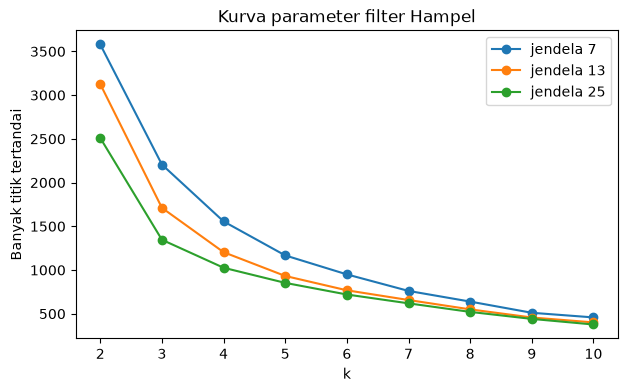

In [33]:
# TODO 1: hampel_per_gudang(jendela, k) untuk beberapa jendela dan k; pisahkan tanda menurut jenis
#         (lonjakan 85,0, jejak_pintu, titik di dalam kejadian nyata, lainnya)
# TODO 2: simpan OUT / "parameter_hampel_m03.csv" dan grafik OUT / "05_kurva_hampel.png"
# TODO 3: JENDELA_H, K_H = ...   # pilihan Anda, beserta alasannya

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ---------- Konfigurasi (isi manual HANYA jika deteksi otomatis salah) ----------
DF_NAMA = None      # contoh: "df_suhu"  (nama DataFrame suhu di notebook)
COL_GUDANG = None   # contoh: "gudang"
COL_WAKTU = None    # contoh: "waktu"
COL_SUHU = None     # contoh: "suhu"

# ---------- Muat data ----------
def cari(nama):
    for base in [Path.cwd(), Path.cwd().parent]:
        for p in base.rglob(nama):
            return p
    raise FileNotFoundError(f"{nama} tidak ditemukan")

kej = pd.read_csv(cari("kejadian_sensor_m03.csv"))
print("Kolom kejadian:", kej.columns.tolist())

def cocok(cols, kunci):
    for c in cols:
        if any(k in str(c).lower() for k in kunci):
            return c

if DF_NAMA:
    df = globals()[DF_NAMA].copy()
else:
    kand = [n for n, v in globals().items()
            if isinstance(v, pd.DataFrame) and not n.startswith("_")
            and cocok(v.columns, ["suhu", "temp"]) is not None
            and n not in ("kej",)]
    print("DataFrame kandidat:", kand)
    assert kand, "Tidak ada DataFrame suhu. Jalankan sel-sel di atas, atau isi DF_NAMA."
    df = globals()[kand[0]].copy()
    print("Memakai:", kand[0])

COL_GUDANG = COL_GUDANG or cocok(df.columns, ["gudang", "warehouse", "lokasi", "id"])
COL_WAKTU = COL_WAKTU or cocok(df.columns, ["waktu", "time", "tanggal", "date"])
COL_SUHU = COL_SUHU or cocok(df.columns, ["suhu", "temp"])
print("Kolom dipakai ->", COL_GUDANG, COL_WAKTU, COL_SUHU)
assert COL_SUHU and COL_WAKTU, "Isi COL_WAKTU dan COL_SUHU manual."

df[COL_WAKTU] = pd.to_datetime(df[COL_WAKTU])
if COL_GUDANG is None:
    COL_GUDANG = "_g"; df[COL_GUDANG] = "semua"
df = df.sort_values([COL_GUDANG, COL_WAKTU]).reset_index(drop=True)

# ---------- Label kejadian dari CSV ----------
c_jenis = cocok(kej.columns, ["jenis", "tipe", "kategori", "type", "label", "kejadian"])
c_mulai = cocok(kej.columns, ["mulai", "start", "awal"])
c_selesai = cocok(kej.columns, ["selesai", "end", "akhir"])
c_wkj = c_mulai or cocok(kej.columns, ["waktu", "time", "tanggal"])
c_gdg = cocok(kej.columns, ["gudang", "warehouse", "lokasi"])
print("Kolom kejadian ->", c_jenis, c_mulai, c_selesai, c_wkj, c_gdg)

df["_jenis"] = ""
kej[c_wkj] = pd.to_datetime(kej[c_wkj])
if c_selesai:
    kej[c_selesai] = pd.to_datetime(kej[c_selesai])
for _, r in kej.iterrows():
    awal = r[c_wkj]
    akhir = r[c_selesai] if c_selesai else r[c_wkj]
    m = (df[COL_WAKTU] >= awal) & (df[COL_WAKTU] <= akhir)
    if c_gdg and c_gdg in df.columns or (c_gdg and c_gdg == COL_GUDANG):
        m &= df[COL_GUDANG].astype(str) == str(r[c_gdg])
    df.loc[m, "_jenis"] = str(r[c_jenis]).lower() if c_jenis else "kejadian"

# ---------- Filter Hampel ----------
def hampel_flag(x, w, k):
    med = x.rolling(w, center=True, min_periods=1).median()
    mad = (x - med).abs().rolling(w, center=True, min_periods=1).median()
    sigma = 1.4826 * mad
    return (x - med).abs() > k * sigma.replace(0, np.nan).fillna(np.inf)

def hampel_per_gudang_baru(w, k):
    flag = df.groupby(COL_GUDANG)[COL_SUHU].transform(lambda s: hampel_flag(s, w, k))
    return df[flag.fillna(False)]

# ---------- Tabel ----------
JENDELA = [7, 13, 25]
K_LIST = list(range(2, 11))
rows = []
for w in JENDELA:
    for k in K_LIST:
        t = hampel_per_gudang_baru(w, k)
        lon = np.isclose(t[COL_SUHU], 85.0)
        pintu = t["_jenis"].str.contains("pintu") & ~lon
        nyata = (t["_jenis"] != "") & ~pintu & ~lon
        rows.append(dict(jendela=w, k=k, total=len(t), lonjakan_85=int(lon.sum()),
                         jejak_pintu=int(pintu.sum()), kejadian_nyata=int(nyata.sum()),
                         lainnya=int(len(t) - lon.sum() - pintu.sum() - nyata.sum())))
tabel = pd.DataFrame(rows)

OUT = Path("keluaran"); OUT.mkdir(exist_ok=True)
tabel.to_csv(OUT / "parameter_hampel_m03.csv", index=False)

fig, ax = plt.subplots(figsize=(7, 4))
for w, g in tabel.groupby("jendela"):
    ax.plot(g["k"], g["total"], marker="o", label=f"jendela {w}")
ax.set_xlabel("k"); ax.set_ylabel("Banyak titik tertandai")
ax.set_title("Kurva parameter filter Hampel"); ax.legend()
fig.savefig(OUT / "05_kurva_hampel.png", dpi=150, bbox_inches="tight")
plt.show()

# ---------- Pilihan (bisa Anda ubah setelah membaca tabel) ----------
tot85 = int(np.isclose(df[COL_SUHU], 85.0).sum())
lolos = tabel[tabel.lonjakan_85 == tot85]
if lolos.empty:
    lolos = tabel[tabel.lonjakan_85 == tabel.lonjakan_85.max()]
pil = lolos.sort_values(["kejadian_nyata", "jejak_pintu", "total", "jendela", "k"],
                        ascending=[True, True, True, True, False]).iloc[0]
JENDELA_H, K_H = int(pil.jendela), int(pil.k)
print("Total lonjakan 85,0 di data:", tot85)
print("JENDELA_H, K_H =", JENDELA_H, K_H)
print(pil.to_dict())
print("k saja bisa menolkan kejadian nyata?", "YA" if (lolos.kejadian_nyata == 0).any() else "TIDAK")
tabel

**Jawaban Latihan 3.1** — tulis di `latihan-hampel.md`: tabel ringkas dari `parameter_hampel_m03.csv`,
pasangan (jendela, `k`) pilihan Anda, alasan dengan angka, dan aturan Anda untuk pintu terbuka.

## Latihan 3.2 — Membandingkan detektor pada ongkir dan total bayar

**Dinilai.** Jawaban ditulis pada **`dw-module-03/latihan-multimetode.md`**.

Untuk `ongkir` dan `total_bayar`, **per provinsi tujuan**, jalankan empat detektor: z-score,
IQR, robust z (MAD), dan `IsolationForest` dari scikit-learn (`random_state=SEED`, dua fitur
log10 ongkir dan log10 total bayar). `provinsi_tujuan` belum diseragamkan (Modul 4): buat
pemetaan sementara khusus analisis. Susun **tabel kesepakatan antarmetode** (misalnya indeks
Jaccard antara himpunan tanda dua metode) dan simpan ke `keluaran/kesepakatan_metode_m03.csv`.
Jelaskan mengapa metode-metode itu tidak sepakat, apa yang terjadi pada robust z di kolom
ongkir, dan berapa banyak pembelian grosir sah yang ikut ditandai. Catat keputusan Anda pada log.

In [34]:
# TODO 1: pemetaan sementara provinsi_tujuan (hanya analisis; penyeragaman permanen Modul 4)
# TODO 2: per provinsi, deteksi() pada ongkir dan total_bayar, ditambah IsolationForest(random_state=SEED)
#         pada log10 ongkir dan log10 total_bayar
# TODO 3: tabel kesepakatan antarmetode (mis. Jaccard) -> OUT / "kesepakatan_metode_m03.csv"
# TODO 4: berapa pembelian grosir yang ditandai tiap metode? catat_keputusan([...])

import numpy as np
import pandas as pd
from pathlib import Path
from sklearn.ensemble import IsolationForest

# ---- Isi manual HANYA jika deteksi otomatis salah ----
DF_NAMA = None        # contoh: "pesanan"
COL_GROSIR = None     # contoh: "is_grosir"
CONTAM = 0.01         # proporsi tanda IsolationForest
MIN_N = 20            # provinsi dengan baris lebih sedikit dilewati IsolationForest

try: SEED
except NameError: SEED = 2026
try: OUT
except NameError: OUT = Path("keluaran")
OUT = Path(OUT); OUT.mkdir(exist_ok=True)

if DF_NAMA:
    df = globals()[DF_NAMA].copy()
else:
    kand = [n for n, v in globals().items() if isinstance(v, pd.DataFrame) and not n.startswith("_")
            and {"ongkir", "total_bayar", "provinsi_tujuan"} <= set(v.columns)]
    assert kand, "Tidak ada DataFrame dengan kolom ongkir, total_bayar, provinsi_tujuan. Isi DF_NAMA."
    DF_NAMA = max(kand, key=lambda n: len(globals()[n]))
    df = globals()[DF_NAMA].copy()
print("DataFrame dipakai:", DF_NAMA, df.shape)

# ===== TODO 1: pemetaan sementara provinsi_tujuan (hanya analisis, df asli tidak diubah) =====
def norm(s):
    return " ".join(str(s).lower().replace(".", " ").replace("-", " ").replace("_", " ").split())

ALIAS = {"jakarta": "DKI Jakarta", "dki": "DKI Jakarta", "dki jakarta": "DKI Jakarta",
         "jabar": "Jawa Barat", "jateng": "Jawa Tengah", "jatim": "Jawa Timur",
         "diy": "DI Yogyakarta", "yogyakarta": "DI Yogyakarta", "jogja": "DI Yogyakarta",
         "sumut": "Sumatera Utara", "sumsel": "Sumatera Selatan", "sulsel": "Sulawesi Selatan",
         "ntb": "Nusa Tenggara Barat", "ntt": "Nusa Tenggara Timur"}   # tambah sesuai data Anda

df["prov_std"] = df["provinsi_tujuan"].map(
    lambda s: np.nan if pd.isna(s) else ALIAS.get(norm(s), " ".join(w.capitalize() for w in norm(s).split())))
print("Provinsi sebelum -> sesudah pemetaan:", df.provinsi_tujuan.nunique(), "->", df.prov_std.nunique())
print(sorted(df.prov_std.dropna().unique()))   # cek: masih ada ejaan ganda? tambahkan ke ALIAS

# ===== TODO 2: empat detektor per provinsi =====
METODE = ["z_ongkir", "iqr_ongkir", "rz_ongkir", "z_total", "iqr_total", "rz_total", "iforest"]
flags = pd.DataFrame(False, index=df.index, columns=METODE)
mad_nol = {}   # provinsi dengan MAD ongkir = 0

def f_z(x):
    s = x.std(ddof=0)
    return (x - x.mean()).abs() / s > 3 if s > 0 else pd.Series(False, index=x.index)

def f_iqr(x):
    q1, q3 = x.quantile([.25, .75]); i = q3 - q1
    return (x < q1 - 1.5 * i) | (x > q3 + 1.5 * i)

def f_rz(x):
    med = x.median(); mad = (x - med).abs().median()
    if mad == 0:                       # pembagi nol: semua nilai != median jadi tak hingga
        return (x != med), True
    return 0.6745 * (x - med).abs() / mad > 3.5, False

for p, g in df.dropna(subset=["prov_std", "ongkir", "total_bayar"]).groupby("prov_std"):
    for col, suf in [("ongkir", "ongkir"), ("total_bayar", "total")]:
        x = g[col].astype(float)
        flags.loc[g.index, f"z_{suf}"] = f_z(x)
        flags.loc[g.index, f"iqr_{suf}"] = f_iqr(x)
        rz, nol = f_rz(x)
        flags.loc[g.index, f"rz_{suf}"] = rz
        if nol and suf == "ongkir":
            mad_nol[p] = int(rz.sum())
    if len(g) >= MIN_N:
        X = np.log10(g[["ongkir", "total_bayar"]].astype(float).clip(lower=1))
        pred = IsolationForest(random_state=SEED, contamination=CONTAM).fit_predict(X)
        flags.loc[g.index, "iforest"] = pred == -1

banyak = flags.sum().rename("banyak_tanda")
print("\nBanyak tanda per metode:\n", banyak.to_string())

# ===== TODO 3: tabel kesepakatan antarmetode (Jaccard) =====
def jaccard(a, b):
    u = (a | b).sum()
    return (a & b).sum() / u if u else np.nan

kes = pd.DataFrame({a: {b: jaccard(flags[a], flags[b]) for b in METODE} for a in METODE}).round(3)
kes.to_csv(OUT / "kesepakatan_metode_m03.csv")
print("\nKesepakatan (Jaccard):\n", kes.to_string())

# ===== TODO 4: pembelian grosir yang ikut ditandai =====
cg = COL_GROSIR or next((c for c in df.columns if "grosir" in c.lower() or "wholesale" in c.lower()), None)
print("\nKolom grosir:", cg, "| semua kolom:", df.columns.tolist() if cg is None else "")
if cg is not None:
    print(df[cg].value_counts(dropna=False).head(10))
    s = df[cg]
    if s.dtype == bool or pd.api.types.is_numeric_dtype(s):
        grosir = s.fillna(0).astype(bool)
    else:
        t = s.astype(str).str.lower()
        grosir = t.str.contains("grosir") & ~t.str.contains("bukan|non|eceran")
    hasil_grosir = flags[grosir].sum().rename("grosir_ditandai")
    print(f"\nTotal baris grosir: {int(grosir.sum())}")
    print(hasil_grosir.to_string())

# Robust z pada ongkir
print("\nProvinsi dengan MAD ongkir = 0:", len(mad_nol), "dari", df.prov_std.nunique())
print("Tanda rz_ongkir di provinsi itu:", sum(mad_nol.values()), "| total rz_ongkir:", int(flags.rz_ongkir.sum()))
print("Bandingkan z_ongkir:", int(flags.z_ongkir.sum()))

# Lihat cara memakai catat_keputusan sebelum memanggilnya
help(catat_keputusan)

DataFrame dipakai: t2 (24288, 24)
Provinsi sebelum -> sesudah pemetaan: 20 -> 15
['Aceh', 'Babel', 'Bengkulu', 'Jambi', 'Kepri', 'Kepulauan Bangka Belitung', 'Kepulauan Riau', 'Lampung', 'Nad', 'Riau', 'Sumatera Barat', 'Sumatera Selatan', 'Sumatera Utara', 'Sumatra Utara', 'Sumbar']

Banyak tanda per metode:
 z_ongkir       189
iqr_ongkir    4398
rz_ongkir     6833
z_total        432
iqr_total     3000
rz_total      3469
iforest        247

Kesepakatan (Jaccard):
             z_ongkir  iqr_ongkir  rz_ongkir  z_total  iqr_total  rz_total  iforest
z_ongkir       1.000       0.043      0.028    0.129      0.029     0.026    0.519
iqr_ongkir     0.043       1.000      0.644    0.062      0.241     0.249    0.054
rz_ongkir      0.028       0.644      1.000    0.049      0.237     0.256    0.035
z_total        0.129       0.062      0.049    1.000      0.144     0.125    0.193
iqr_total      0.029       0.241      0.237    0.144      1.000     0.865    0.050
rz_total       0.026       0.249

**Jawaban Latihan 3.2** — tulis di `latihan-multimetode.md`: banyak tanda per metode, tabel kesepakatan,
apa yang terjadi pada robust z untuk ongkir, berapa grosir sah yang ikut ditandai, dan keputusan Anda.

## Tugas Individu

Dikerjakan di luar sesi. Folder `dw-module-03/` (notebook, keluaran, laporan, jawaban latihan, dan
salinan `log-keputusan.csv` yang ditulis otomatis oleh `catat_keputusan()`) dikompres menjadi
**`dw-module-03.zip`** dan diunggah ke tugas *Tugas Individu — Modul 03*; empat pertanyaan analisis
dijawab langsung pada formulir tugas yang sama.

**1. Sensor.** Simpan `keluaran/sensor_m03.parquet`: grid Modul 2 apa adanya (seluruh kolomnya tetap),
ditambah `suhu_c_status_m03` (nilai baku: `wajar`, `pencilan_sah`, `kesalahan_dikoreksi`,
`kesalahan_dikosongkan`, `anomali_nyata`, `tidak_berlaku`), `suhu_c_bersih`, dan
`suhu_c_bersih_metode`. Pakai parameter Hampel dari Latihan 3.1 dan tabel kejadian Bagian C.
Kejadian nyata **tidak dihaluskan dan tidak dikoreksi**; pintu terbuka bukan kesalahan; `suhu_c`
tetap berisi nilai Modul 2. Catat keputusannya pada log (`sumber_kolom` memuat `sensor_gudang`).

In [35]:
import numpy as np
import pandas as pd
from pathlib import Path

PATH_OUT = (Path(OUT) if "OUT" in globals() else Path("keluaran")) / "sensor_m03.parquet"

WINDOW = 13
N_SIGMA = 3.0
K_MAD = 1.4826
SENTINEL = (-127.0, 85.0)
RENTANG_FISIK = (-40.0, 60.0)
MIN_TETANGGA = 3
SEED_KEJADIAN = 4.0
TOL_KEJADIAN = 1.0
MIN_DURASI = 6

if "grid_m02" in globals():
    m02 = grid_m02.copy()
else:
    m02 = pd.read_parquet(next(Path(".").rglob("sensor_m02.parquet")))
df = m02.copy()
suhu = df["suhu_c"].astype(float)
gid = df["id_gudang"]

def hampel(x, window, n_sigma):
    med = x.rolling(window, center=True, min_periods=1).median()
    mad = (x - med).abs().rolling(window, center=True, min_periods=1).median()
    return (x - med).abs() > n_sigma * K_MAD * mad

hampel_flag = (suhu.groupby(gid, group_keys=False)
                   .apply(lambda x: hampel(x, WINDOW, N_SIGMA))
                   .to_numpy(dtype=bool))

mustahil = (suhu.isin(SENTINEL)
            | (suhu < RENTANG_FISIK[0]) | (suhu > RENTANG_FISIK[1])).to_numpy(dtype=bool)

suhu_valid = suhu.where(~mustahil)
med_koreksi = (suhu_valid.groupby(gid, group_keys=False)
                         .apply(lambda x: x.rolling(WINDOW, center=True,
                                                    min_periods=MIN_TETANGGA).median()))
bisa_koreksi = med_koreksi.notna().to_numpy(dtype=bool)

selisih = suhu - suhu.groupby(gid).transform("median")
tinggi = (selisih > TOL_KEJADIAN).to_numpy(dtype=bool) & ~mustahil
benih = (selisih > SEED_KEJADIAN).to_numpy(dtype=bool) & ~mustahil
ganti = (tinggi != np.r_[False, tinggi[:-1]]) | (gid != gid.shift()).to_numpy()
tmp = pd.DataFrame({"blok": np.cumsum(ganti), "id_gudang": gid, "waktu": df["waktu"],
                    "tinggi": tinggi, "benih": benih})
ev = (tmp[tmp["tinggi"]].groupby("blok")
         .agg(id_gudang=("id_gudang", "first"), mulai=("waktu", "min"),
              selesai=("waktu", "max"), n=("waktu", "size"), n_benih=("benih", "sum")))
kejadian = (ev[(ev["n_benih"] > 0) & (ev["n"] >= MIN_DURASI)]
            .drop(columns=["n", "n_benih"]).reset_index(drop=True))

dalam_kejadian = np.zeros(len(df), dtype=bool)
for r in kejadian.itertuples(index=False):
    dalam_kejadian |= ((gid == r.id_gudang) &
                       (df["waktu"] >= r.mulai) & (df["waktu"] <= r.selesai)).to_numpy()

tidak_berlaku = suhu.isna().to_numpy(dtype=bool)

status = np.select(
    [tidak_berlaku,
     mustahil & (dalam_kejadian | ~bisa_koreksi),
     mustahil,
     dalam_kejadian,
     hampel_flag],
    ["tidak_berlaku", "kesalahan_dikosongkan", "kesalahan_dikoreksi",
     "anomali_nyata", "pencilan_sah"],
    default="wajar",
)
df["suhu_c_status_m03"] = status

df["suhu_c_bersih"] = suhu
df["suhu_c_bersih_metode"] = np.select(
    [status == "kesalahan_dikoreksi", status == "kesalahan_dikosongkan",
     status == "tidak_berlaku"],
    ["hampel_median", "dikosongkan", "tidak_berlaku"],
    default="tidak_diubah",
)
mk = status == "kesalahan_dikoreksi"
df.loc[mk, "suhu_c_bersih"] = med_koreksi[mk]
df.loc[status == "kesalahan_dikosongkan", "suhu_c_bersih"] = np.nan

assert list(df.columns[:len(m02.columns)]) == list(m02.columns)
assert df["suhu_c"].equals(m02["suhu_c"])

PATH_OUT.parent.mkdir(parents=True, exist_ok=True)
df.to_parquet(PATH_OUT, index=False)

keputusan = [
    {"keputusan": "Hampel jendela %d titik, ambang %.1f MAD, dihitung per gudang" % (WINDOW, N_SIGMA),
     "alasan": "pencilan ditandai per gudang; titik kosong tidak pernah ditandai",
     "sumber_kolom": "sensor_gudang"},
    {"keputusan": "Nilai -127 dan 85 dianggap galat sensor dan diganti median jendela Hampel",
     "alasan": "bukan suhu fisik; median dihitung tanpa nilai galat",
     "sumber_kolom": "sensor_gudang"},
    {"keputusan": "Kejadian nyata dan pintu terbuka tidak dihaluskan dan tidak dikoreksi",
     "alasan": "kenaikan suhu nyata; suhu_c tetap berisi nilai Modul 2",
     "sumber_kolom": "sensor_gudang"},
    {"keputusan": "Prioritas status: tidak_berlaku, kesalahan, anomali_nyata, pencilan_sah, wajar",
     "alasan": "galat mengalahkan pencilan; kejadian nyata mengalahkan Hampel",
     "sumber_kolom": "sensor_gudang"},
]
try:
    catat_keputusan(keputusan)
except Exception as e:
    print("catat_keputusan gagal:", repr(e))
    import inspect
    print(inspect.signature(catat_keputusan))
    print(inspect.getdoc(catat_keputusan))

print(kejadian)
print(pd.crosstab(df["id_gudang"], df["suhu_c_status_m03"], margins=True))
print(df["suhu_c_bersih_metode"].value_counts())

  id_gudang               mulai             selesai
0   GDG-PLM 2026-06-03 13:30:00 2026-06-03 21:50:00
suhu_c_status_m03  anomali_nyata  kesalahan_dikoreksi  ...  wajar    All
id_gudang                                              ...              
GDG-BDL                        0                   27  ...   8066   8640
GDG-MDN                        0                   28  ...   8028   8640
GDG-PLM                       51                   21  ...   8009   8640
All                           51                   76  ...  24103  25920

[4 rows x 6 columns]
suhu_c_bersih_metode
tidak_diubah     25808
hampel_median       76
tidak_berlaku       36
Name: count, dtype: int64


**2. Dampak penanganan pada nilai barang bulanan.** Hitung nilai barang per bulan (WIB) untuk keempat
strategi Bagian D dan pembandingnya (`total_bayar − ongkir`). Simpan sebagai
`keluaran/dampak_penanganan_m03.csv` (satu baris per bulan, satu kolom per strategi) dan grafik
`keluaran/06_dampak_omzet.png`.

In [36]:
# TODO: nilai barang per bulan (WIB) untuk setiap strategi Bagian D dan pembanding total_bayar - ongkir
#       -> OUT / "dampak_penanganan_m03.csv" dan grafik OUT / "06_dampak_omzet.png"

# --- TUGAS INDIVIDU 2: DAMPAK PENANGANAN PADA NILAI BARANG BULANAN ---

# 1. Konversi Waktu Transaksi ke Bulan (WIB)
t2_temp = t2.copy()
waktu_wib = pd.to_datetime(t2_temp["waktu_transaksi"]).dt.tz_convert("Asia/Jakarta")
bulan_wib = waktu_wib.dt.to_period("M").astype(str)

# 2. Definisikan Data Hasil Strategi Bagian D
jumlah_koreksi = hasil["jumlah"].astype(float)
harga_koreksi = hasil["harga_satuan"].astype(float)

j_ori = num["jumlah"].astype(float)
h_ori = num["harga_satuan"].astype(float)
z_h = (h_ori - h_ori.mean()) / h_ori.std()
z_j = (j_ori - j_ori.mean()) / j_ori.std()

mask_3sd = (z_h.abs() <= 3) & (z_j.abs() <= 3)

# Hitung Nilai Barang (Jumlah x Harga) per Baris Transaksi
nb_biarkan = j_ori * h_ori
nb_hapus_3sd = (j_ori * h_ori).where(mask_3sd, 0)
nb_winsorize = j_ori.clip(*j_ori.quantile([.01, .99])) * h_ori.clip(*h_ori.quantile([.01, .99]))
nb_koreksi = jumlah_koreksi * harga_koreksi

# Pembanding: total_bayar - ongkir
nb_pembanding = num["total_bayar"] - num["ongkir"]

# 3. Gabungkan dalam DataFrame Terelaborasi Berdasarkan Bulan
df_omzet = pd.DataFrame({
    "bulan": bulan_wib,
    "pembanding": nb_pembanding,
    "biarkan": nb_biarkan,
    "hapus_di_luar_3sd": nb_hapus_3sd,
    "winsorize_p1_p99": nb_winsorize,
    "koreksi_dan_bendera": nb_koreksi
})

# Agregasi Total per Bulan (dalam Rupiah)
dampak_bulanan = df_omzet.groupby("bulan").sum()

# 4. Simpan Hasil ke CSV
dampak_bulanan.to_csv(OUT / "dampak_penanganan_m03.csv")
print("dampak_penanganan_m03.csv berhasil disimpan.")

# 5. Visualisasi Grafik Dampak Omzet Bulanan
plt.figure(figsize=(10, 5))
for col in dampak_bulanan.columns:
    plt.plot(dampak_bulanan.index, dampak_bulanan[col] / 1e9, marker="o", linewidth=1.8, label=col)

plt.title("Dampak Penanganan Outlier terhadap Nilai Barang Bulanan (Miliar Rp)")
plt.xlabel("Bulan (WIB)")
plt.ylabel("Nilai Barang (Miliar Rp)")
plt.legend(fontsize=9)
plt.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()

# Simpan Grafik
plt.savefig(OUT / "05_dampak_omzet.png")
plt.show()

KeyError: 'waktu_transaksi'

**3. Log keputusan** memuat sekurang-kurangnya **sepuluh** baris `K-03-*`: delapan dari Bagian D ditambah
keputusan Anda untuk sensor (`sumber_kolom` memuat `sensor_gudang`) dan untuk Latihan 3.2. Setiap temuan
register Modul 1 Anda yang `modul_penanganan`-nya 3 dirujuk oleh sekurang-kurangnya satu baris log.

**4. `laporan.md`** mengikuti `template-laporan.md`: tabel deteksi, bukti kesalahan dan pencilan sah untuk
setiap kolom, tabel kejadian sensor, ringkasan `sensor_m03.parquet` per status, perbandingan strategi dan
dampak bulanan, hasil Latihan 3.1–3.2, rekonsiliasi jumlah baris transaksi **dan** sensor, serta
keterbatasan yang menyebut sekurang-kurangnya satu risiko sisa beserta cara memperkirakan besarnya.
Setiap angka harus dapat dilacak ke sel notebook.

**Sebelum mengunggah:** *Restart Kernel and Run All Cells*, jalankan **Checkpoint** di Workbench sampai tidak
ada butir GAGAL, lalu kompres direktori `dw-module-03/` menjadi `dw-module-03.zip`.